# PDAN8412 POE Part 1: Guessing an Author from Writing Style with Recurrent Neural Networks

**Scenario.** I am a data analyst at a large book press. The press wants a fun bot for fans that reads a short passage and guesses which author wrote it, using only the writing style. The bot is built with a recurrent neural network, which is a type of network designed to read text one word at a time.

**Dataset.** I use the Spooky Author Identification dataset from Kaggle (Kaggle, 2017). The file `train.csv` holds 19 579 sentences, each labelled with one of three authors: Edgar Allan Poe (EAP), Mary Shelley (MWS) and H.P. Lovecraft (HPL). The file `test.csv` has no labels, so it cannot be used to measure accuracy. I therefore split `train.csv` into training, validation and test sets myself.

**How this notebook works.** The data analysis uses pandas, and the models are built with TensorFlow and Keras. The notebook first checks the data and explores it in depth, then chooses the model settings from that evidence, then trains and compares four kinds of recurrent model: LSTM, Bidirectional LSTM, GRU and SimpleRNN. It ends with a small function that plays the role of the fan bot. Every code cell is followed by a markdown cell that explains the code in plain English. Every chart is saved as a numbered PNG in the `figures` folder, and every results table is saved in the `outputs` folder, so that the report can be written from them.

## 1. Setup and imports

This section loads the libraries, fixes the random seeds so that results can be repeated, sets up the folder paths and chooses a consistent look for the charts.

In [1]:
import os
import re
import sys
import time
import random
import unicodedata
from pathlib import Path
from collections import Counter

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # keep TensorFlow's start-up messages short

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from wordcloud import WordCloud

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, GRU, SimpleRNN, Bidirectional, Dropout, Dense
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             log_loss, classification_report, confusion_matrix, precision_recall_fscore_support)
from sklearn.utils.class_weight import compute_class_weight

for package in ["stopwords", "wordnet", "punkt_tab"]:      # small text resources used by NLTK
    nltk.download(package, quiet=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 110)

print("Python    :", sys.version.split()[0])
print("NumPy     :", np.__version__)
print("pandas    :", pd.__version__)
print("TensorFlow:", tf.__version__)
print("Devices   :", [d.device_type for d in tf.config.list_physical_devices()])

Python    : 3.11.16
NumPy     : 2.0.2
pandas    : 3.0.5
TensorFlow: 2.18.0
Devices   : ['CPU', 'GPU']


This code brings in every library used in the notebook. Pandas and NumPy handle tables and numbers, Matplotlib and Seaborn draw charts, and SciPy provides the statistical tests. NLTK supplies the stopword list, the word lemmatiser and the tokeniser that the EDA needs, and the word cloud library draws the word clouds. TensorFlow and Keras build the neural networks, and scikit-learn handles splitting, encoding and the evaluation metrics. The code also downloads three small NLTK resources if they are missing. The last lines print the library versions and the processors TensorFlow can see, so it is clear exactly what setup produced the results.

In [2]:
# Fix the random seeds so that every run gives the same splits and the same starting weights.
seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

# The notebook lives in JupyterNotebook/, so the project folder is one level up.
project_dir = Path.cwd().parent
data_path = project_dir / "Traning Data" / "train.csv"   # the folder is spelt "Traning" on disk
fig_dir = project_dir / "figures"
out_dir = project_dir / "outputs"

if not data_path.exists():
    raise FileNotFoundError(
        f"Could not find {data_path}. Open this notebook from the JupyterNotebook folder "
        "so that the project folder sits one level above it."
    )

fig_dir.mkdir(exist_ok=True)
out_dir.mkdir(exist_ok=True)

print("Seed       :", seed)
print("Data file  :", data_path.relative_to(project_dir), f"({data_path.stat().st_size / 1e6:.1f} MB)")
print("Figures dir:", fig_dir.relative_to(project_dir))
print("Outputs dir:", out_dir.relative_to(project_dir))

Seed       : 42
Data file  : Traning Data/train.csv (3.3 MB)
Figures dir: figures
Outputs dir: outputs


This code sets the random seed to 42 for Python, NumPy and TensorFlow. Many steps involve chance, such as shuffling the data and choosing the starting weights of a network, so fixing the seed means that anyone who runs the notebook again gets the same results. The code then works out where the data, the charts and the result tables are stored, using the fact that the notebook sits inside the `JupyterNotebook` folder. It stops with a clear message if the data file cannot be found, and it creates the `figures` and `outputs` folders if they do not exist yet. The data folder is spelt "Traning Data" on disk, so the path uses that exact spelling.

In [3]:
sns.set_theme(style="whitegrid", context="notebook")

author_order = ["EAP", "MWS", "HPL"]
author_names = {"EAP": "Edgar Allan Poe", "MWS": "Mary Shelley", "HPL": "H.P. Lovecraft"}
# One colour per author, taken from a colour-blind friendly palette, reused in every chart.
author_colours = {"EAP": "#0072B2", "MWS": "#009E73", "HPL": "#D55E00"}


def save_figure(filename):
    """Save the current chart into figures/ at 150 dpi, then show it."""
    plt.savefig(fig_dir / filename, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: figures/{filename}")


print({a: f"{author_names[a]} ({author_colours[a]})" for a in author_order})

{'EAP': 'Edgar Allan Poe (#0072B2)', 'MWS': 'Mary Shelley (#009E73)', 'HPL': 'H.P. Lovecraft (#D55E00)'}


This code chooses one clean chart style for the whole notebook and sets up the three authors in a fixed order, with their full names and one fixed colour each. Using the same colour for the same author in every chart makes the charts much easier to read and compare, and the colours come from a palette that stays distinguishable for readers with colour blindness. The `save_figure` function is a small shortcut that saves the current chart as a PNG at 150 dpi inside the `figures` folder and then shows it, so that every chart used in the report is stored on disk automatically.

## 2. Loading and inspecting the data

This section loads the file and looks at its basic shape, its columns, a few example rows, the number of sentences per author, and whether any values are missing or repeated.

In [4]:
df = pd.read_csv(data_path)
print("Shape:", df.shape)
print("Columns:", list(df.columns))
df.head()

Shape: (19579, 3)
Columns: ['id', 'text', 'author']


,id,text,author
0,id26305,"This process, however, afforded me no means of ascertaining the dimensions of my dungeon; as I might make ...",EAP
1,id17569,It never once occurred to me that the fumbling might be a mere mistake.,HPL
2,id11008,"In his left hand was a gold snuff box, from which, as he capered down the hill, cutting all manner of fant...",EAP
3,id27763,"How lovely is spring As we looked from Windsor Terrace on the sixteen fertile counties spread beneath, spe...",MWS
4,id12958,"Finding nothing else, not even gold, the Superintendent abandoned his attempts; but a perplexed look occas...",HPL


This code reads `train.csv` into a table called `df`, then prints how many rows and columns it has and what the columns are called. The first five rows are shown so that the structure is easy to see. Each row is one sentence: `id` is a unique label, `text` is the sentence itself, and `author` is the answer that the model will later try to predict.

**What the output shows.** The file has 19,579 rows and three columns, and the first rows already show the mix of authors and the very different sentence lengths.

In [5]:
df.info()
display(df.describe(include="all"))

<class 'pandas.DataFrame'>
RangeIndex: 19579 entries, 0 to 19578
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      19579 non-null  str  
 1   text    19579 non-null  str  
 2   author  19579 non-null  str  
dtypes: str(3)
memory usage: 459.0 KB


,id,text,author
count,19579,19579,19579
unique,19579,19579,3
top,id26305,"This process, however, afforded me no means of ascertaining the dimensions of my dungeon; as I might make ...",EAP
freq,1,1,7900


This code asks pandas for a technical summary of the table. The `info` output shows the type of each column and how many values are filled in, and `describe` shows the number of unique values and the most common value in each column. Together they confirm that all three columns hold text, that every row is filled in, and that there are three unique authors.

**What the output shows.** All three columns are filled in for every one of the 19,579 rows, every `id` is unique, and there are exactly three authors.

In [6]:
display(df.sample(8, random_state=seed))

,id,text,author
6148,id15695,"The gigantic magnitude and the immediately available nature of the sum, dazzled and bewildered all who tho...",EAP
4881,id07954,Shall I disturb this calm by mingling in the world?,MWS
16114,id16303,He had seen so many customs and witnessed so great a variety of moral creeds that he had been obliged to f...,MWS
738,id07932,"We went up stairs into the chamber where the body of Mademoiselle L'Espanaye had been found, and where bot...",EAP
13435,id20875,"Over those horrors the evil moon now hung very low, but the puffy worms of the sea need no moon to feed by.",HPL
4706,id14743,"She listened to me as she had done to the narration of my adventures, and sometimes took an interest in th...",MWS
11277,id07281,"His chief amusements were gunning and fishing, or sauntering along the beach and through the myrtles, in q...",EAP
18884,id09240,I have not the slightest fear for the result.,EAP


This code shows eight randomly chosen sentences, with the seed fixed so that the same eight appear every time. Reading real examples is important before any modelling. It shows that the sentences are complete pieces of literary prose of very different lengths, that they contain punctuation such as commas, semicolons and quotation marks, and that they are written in an older style of English.

**What the output shows.** The sample confirms that the sentences are grammatical pieces of prose. Some are short and plain, such as "I have not the slightest fear for the result", while others are long and use semicolons and formal, older vocabulary, so length alone will not identify an author.

In [7]:
class_counts = df["author"].value_counts()
class_table = pd.DataFrame({
    "author_name": class_counts.index.map(author_names),
    "sentences": class_counts.values,
    "percent": (class_counts.values / len(df) * 100).round(1),
}, index=class_counts.index)
display(class_table)
print("Number of classes:", df["author"].nunique())

,author_name,sentences,percent
author,,,
EAP,Edgar Allan Poe,7900,40.3
MWS,Mary Shelley,6044,30.9
HPL,H.P. Lovecraft,5635,28.8


Number of classes: 3


This code counts how many sentences belong to each author and turns the counts into percentages. Knowing the class balance matters because a model trained on unbalanced classes can simply favour the biggest class and still look accurate. It also tells us what accuracy a lazy model that always guesses the biggest class would score, which is the baseline any real model has to beat.

**What the output shows.** Edgar Allan Poe has 7,900 sentences (40.3 percent), Mary Shelley has 6,044 (30.9 percent) and H.P. Lovecraft has 5,635 (28.8 percent). The classes are mildly unbalanced, and a lazy model that always guessed Poe would already be right about 40 percent of the time, so 40 percent is the score every real model has to beat.

In [8]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicate rows          :", df.duplicated().sum())
print("Duplicate ids           :", df["id"].duplicated().sum())
print("Duplicate sentences     :", df["text"].duplicated().sum())

# Also catch sentences that only differ by capital letters or spacing.
normalised = df["text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
print("Duplicates ignoring case and spacing:", normalised.duplicated().sum())
print("Sentences labelled with more than one author:", (df.groupby("text")["author"].nunique() > 1).sum())

Missing values per column:
id        0
text      0
author    0
dtype: int64

Duplicate rows          : 0
Duplicate ids           : 0
Duplicate sentences     : 0
Duplicates ignoring case and spacing: 1
Sentences labelled with more than one author: 0


This code checks for the most common data problems. It counts missing values in every column, and it counts duplicated rows, duplicated ids and duplicated sentences. It then repeats the sentence check after making everything lower case and tidying the spaces, in case two sentences differ only in trivial ways. Finally it checks whether the same sentence appears under two different authors, which would give the model contradictory answers. Duplicates matter for a second reason: if the same sentence landed in both the training set and the test set, the test score would be unfairly high.

**What the output shows.** There are no missing values, no duplicated rows, no duplicated ids and no duplicated sentences, and no sentence appears under two authors. The case-insensitive check finds exactly one extra pair, two Poe sentences that differ only in whether the word "Nature" starts with a capital letter. One pair is too few to matter.

## 3. Data quality checks

This section looks for problems that could mislead the model or the analysis: empty or very short texts, extreme length outliers, and unusual characters. Each check ends in a decision, and the decisions are collected into one summary table.

In [9]:
df["char_count"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()

print("Empty or blank texts:", (df["text"].str.strip() == "").sum())
print("Texts with fewer than 4 words:", (df["word_count"] < 4).sum())
short = df[df["word_count"] < 4].sort_values("word_count")[["author", "text", "word_count"]]
display(short.head(10))
print(short["author"].value_counts().to_dict())

Empty or blank texts: 0
Texts with fewer than 4 words: 25


,author,text,word_count
18127,MWS,Shakspeare's Sonnets.,2
18064,MWS,Shakespeare's Sonnets.,2
6936,EAP,"""PIQUANT EXPRESSIONS.",2
9250,EAP,"""EXTRAORDINARY MURDERS.",2
2403,EAP,"Yours everlastingly, PUNDITA.",3
16957,EAP,The populace encored.,3
16804,EAP,"""Yours sincerely, ""STUBBS.""",3
15573,EAP,After much hesitation.,3
13401,EAP,Rousseau Nouvelle Heloise.,3
12247,EAP,These latter theorize.,3


{'EAP': 17, 'MWS': 8}


This code adds two new columns that count the characters and the words in each sentence, since the length of a sentence is central to how a recurrent network is set up. It then looks for empty texts and for very short texts of fewer than four words, and lists the shortest ones with their authors. Very short texts are worth a look because a title or a fragment like "Yours everlastingly" contains almost no information about writing style, so the model is unlikely to classify it well.

**What the output shows.** Only 25 sentences (17 by Poe and 8 by Shelley) have fewer than four words, and none are empty. Reading them shows they are mostly chapter titles or fragments such as "Shakespeare's Sonnets" and "The populace encored", which hold almost no writing style. There are so few of them that they are kept.

In [10]:
q1, q3 = df["word_count"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)          # the usual boxplot rule for an outlier
percentiles = df["word_count"].quantile([0.5, 0.9, 0.95, 0.99, 0.999]).rename("words")
display(percentiles.to_frame())

print(f"Upper outlier fence (Q3 + 1.5 x IQR): {upper_fence:.0f} words")
print("Sentences above the fence     :", (df["word_count"] > upper_fence).sum())
print("Sentences over 100 words      :", (df["word_count"] > 100).sum())
print("Sentences over 200 words      :", (df["word_count"] > 200).sum())
print("Outliers by author            :", df.loc[df["word_count"] > upper_fence, "author"].value_counts().to_dict())

longest = df.nlargest(5, "word_count")[["author", "word_count", "text"]]
display(longest.assign(text=longest["text"].str[:110] + "..."))

,words
0.500,23.000
0.900,48.000
0.950,58.000
0.990,85.000
0.999,147.422


Upper outlier fence (Q3 + 1.5 x IQR): 62 words
Sentences above the fence     : 726
Sentences over 100 words      : 88
Sentences over 200 words      : 7
Outliers by author            : {'EAP': 353, 'MWS': 248, 'HPL': 125}


,author,word_count,text
9215,MWS,861,Diotima approached the fountain seated herself on a mossy mound near it and her disciples placed themselve...
18107,MWS,594,Oh no I will become wise I will study my own heart and there discovering as I may the spring of the virtue...
10939,MWS,445,They are gone for ever great as my power is I cannot recall them to you if indeed I wave my wand over you ...
3956,MWS,377,"To chambers of painted state farewell To midnight revelry, and the panting emulation of beauty, to costly ..."
4184,MWS,335,As for those who in your world knew not the loveliness of benevolence justice they are placed apart some c...


This code studies unusually long sentences. It prints the median and several high percentiles of the word counts, and it works out the standard boxplot cut-off for an outlier, which is the third quartile plus one and a half times the spread between the first and third quartiles. It counts how many sentences go beyond that cut-off, beyond 100 words and beyond 200 words, shows which authors they belong to, and prints the beginning of the five longest sentences. A few extremely long sentences can distort a recurrent network, because every sentence is later padded or cut to one common length and one giant sentence should not decide that length.

**What the output shows.** The median sentence has 23 words and 95 percent have 58 words or fewer. The boxplot rule marks anything above 62 words as an outlier, which affects 726 sentences (3.7 percent): 353 by Poe, 248 by Shelley and 125 by Lovecraft. Only 88 sentences pass 100 words and only 7 pass 200. The longest sentence has 861 words and belongs to Shelley. Its opening words carry no punctuation at all, so it looks like several sentences run together, probably because full stops were lost when the data was prepared, although only the start was read. These extreme cases are a data quality issue, and they are handled by cutting every sentence to one common length rather than by deleting them.

In [11]:
non_ascii = Counter(ch for text in df["text"] for ch in text if ord(ch) > 127)
odd_characters = pd.DataFrame(
    [(ch, unicodedata.name(ch, "UNKNOWN"), n) for ch, n in non_ascii.most_common()],
    columns=["character", "unicode_name", "count"])
display(odd_characters.head(12))

df["has_non_ascii"] = df["text"].map(lambda t: any(ord(ch) > 127 for ch in t))
print("Sentences with non-ASCII characters:", df["has_non_ascii"].sum())
display(pd.crosstab(df["author"], df["has_non_ascii"], margins=True))

punctuation = Counter(ch for text in df["text"] for ch in text if not ch.isalnum() and not ch.isspace())
punctuation_table = pd.DataFrame(punctuation.most_common(), columns=["character", "count"])
display(punctuation_table.T)
absent = [m for m in ["!", "-", "–", "—", "(", ")", "…"] if m not in punctuation]
print("Common marks that never appear:", absent)
print("Sentences containing digits   :", df["text"].str.contains(r"\d").sum())
print("Leading or trailing spaces    :", (df["text"] != df["text"].str.strip()).sum())
print("Double spaces                 :", df["text"].str.contains("  ").sum())

,character,unicode_name,count
0,é,LATIN SMALL LETTER E WITH ACUTE,62
1,æ,LATIN SMALL LETTER AE,46
2,ê,LATIN SMALL LETTER E WITH CIRCUMFLEX,30
3,ö,LATIN SMALL LETTER O WITH DIAERESIS,19
4,è,LATIN SMALL LETTER E WITH GRAVE,15
5,ë,LATIN SMALL LETTER E WITH DIAERESIS,12
6,à,LATIN SMALL LETTER A WITH GRAVE,10
7,ô,LATIN SMALL LETTER O WITH CIRCUMFLEX,8
8,ñ,LATIN SMALL LETTER N WITH TILDE,7
9,ä,LATIN SMALL LETTER A WITH DIAERESIS,7


Sentences with non-ASCII characters: 197


has_non_ascii,False,True,All
author,,,
EAP,7770,130,7900
HPL,5568,67,5635
MWS,6044,0,6044
All,19382,197,19579


,0,1,2,3,4,5,6
character,",",.,;,"""",',?,:
count,38220,20075,5159,4969,3520,1098,562


Common marks that never appear: ['!', '-', '–', '—', '(', ')', '…']
Sentences containing digits   : 0
Leading or trailing spaces    : 0
Double spaces                 : 0


This code hunts for encoding oddities and inventories the punctuation. It lists every character outside plain English letters, such as accented letters and Greek letters, together with its official Unicode name, and it counts how many sentences contain them for each author. It then builds a full list of every punctuation character in the data and checks for common marks that never appear, and it also checks for digits, stray spaces and double spaces. These checks matter for two reasons. Characters that appear for only one author could become an accidental shortcut for the model, and punctuation that is missing from the file cannot be used as a style clue, which affects the choice of features later.

**What the output shows.** Exactly 197 sentences (1.0 percent) contain accented or special letters, such as "é", "æ" and "ê". They occur in 130 Poe sentences and 67 Lovecraft sentences and in none of Shelley's. This is a genuine trait of the authors, since Poe often quotes French, but it is also a possible shortcut, because an accented letter would tell the model "not Shelley". Because only 1 percent of sentences are involved, the effect is small, and it is listed as a pitfall for the report. The punctuation inventory shows only seven marks: commas, full stops, semicolons, double quotation marks, apostrophes, question marks and colons. There are no exclamation marks, hyphens, dashes, brackets or ellipses anywhere, and there are no digits or stray spaces. The missing marks matter because Poe is famous for his dashes and exclamations, so the file has lost part of the style that a human reader would see.

In [12]:
quality = pd.DataFrame([
    ["Missing values", f"{df[['id', 'text', 'author']].isnull().sum().sum()} missing cells",
     "Nothing to fill or remove."],
    ["Duplicate sentences", f"{df['text'].duplicated().sum()} duplicated texts",
     "Nothing to remove, so no sentence can leak between the training and test sets."],
    ["Near-duplicate sentences", f"{normalised.duplicated().sum()} pair differing only in a capital letter (same author)",
     "Keep both. One pair cannot change the results."],
    ["Empty or blank texts", f"{(df['text'].str.strip() == '').sum()} empty texts",
     "Nothing to remove."],
    ["Very short texts (under 4 words)", f"{(df['word_count'] < 4).sum()} sentences",
     "Keep them. They are real sentences and are few, and a real fan may also type a short line."],
    ["Extreme long sentences", f"{(df['word_count'] > upper_fence).sum()} above {upper_fence:.0f} words, longest {df['word_count'].max()} words",
     "Keep them but cut every sentence to one common length later, so that no single sentence sets the size."],
    ["Non-ASCII characters", f"{df['has_non_ascii'].sum()} sentences, {len(non_ascii)} distinct characters",
     "Keep them, only lower-case the text. They are genuine features of the authors' writing, but see the pitfalls in the report."],
    ["Missing punctuation types", "No exclamation marks, hyphens or dashes in the file",
     "Report it, and leave those features out of the style charts because they are always zero."],
    ["Class imbalance", f"Largest class {class_table['percent'].max()} percent, smallest {class_table['percent'].min()} percent",
     "Mild imbalance. Use stratified splits, macro metrics, and test class weights as an improvement."],
], columns=["Check", "Finding", "Decision"])
display(quality)
quality.to_csv(out_dir / "data_quality_summary.csv", index=False)

,Check,Finding,Decision
0,Missing values,0 missing cells,Nothing to fill or remove.
1,Duplicate sentences,0 duplicated texts,"Nothing to remove, so no sentence can leak between the training and test sets."
2,Near-duplicate sentences,1 pair differing only in a capital letter (same author),Keep both. One pair cannot change the results.
3,Empty or blank texts,0 empty texts,Nothing to remove.
4,Very short texts (under 4 words),25 sentences,"Keep them. They are real sentences and are few, and a real fan may also type a short line."
5,Extreme long sentences,"726 above 62 words, longest 861 words","Keep them but cut every sentence to one common length later, so that no single sentence sets the size."
6,Non-ASCII characters,"197 sentences, 25 distinct characters","Keep them, only lower-case the text. They are genuine features of the authors' writing, but see the pitfal..."
7,Missing punctuation types,"No exclamation marks, hyphens or dashes in the file","Report it, and leave those features out of the style charts because they are always zero."
8,Class imbalance,"Largest class 40.3 percent, smallest 28.8 percent","Mild imbalance. Use stratified splits, macro metrics, and test class weights as an improvement."


This code gathers everything found so far into one summary table with three columns: the check that was made, what was found, and what will be done about it. The numbers in the table are pulled straight from the earlier results, so the table cannot drift out of date. The table is also saved as a CSV file in the `outputs` folder so that it can be reused in the report. The overall message is that this is a clean dataset with no missing values and no duplicates, and that the main things to manage are a small number of extreme sentences, a mild class imbalance, and some quirks in the characters and punctuation.

**What the output shows.** The table shows that the dataset is clean. The only things that need managing are the small set of very long sentences, the mild class imbalance, the near-duplicate pair, and the character and punctuation quirks. None of these require rows to be deleted.

## 4. Exploratory data analysis

This section explores the sentences in depth. It covers class balance, sentence length, the most common words, word clouds, common word pairs and triples, writing style measurements, and how much vocabulary the three authors share. The exploration uses the whole labelled dataset because it only describes the data and does not train anything.

A note on method. Function words such as "the", "of" and "and", and punctuation marks, carry a lot of an author's writing style. For that reason they are kept in the model input later. In this EDA section only, stopwords are removed and words are reduced to their base forms (lemmatised) in some views, because otherwise the charts of common words show nothing but "the" and "of" and hide the subject matter. Each chart says which version of the text it uses.

### 4a. Class balance

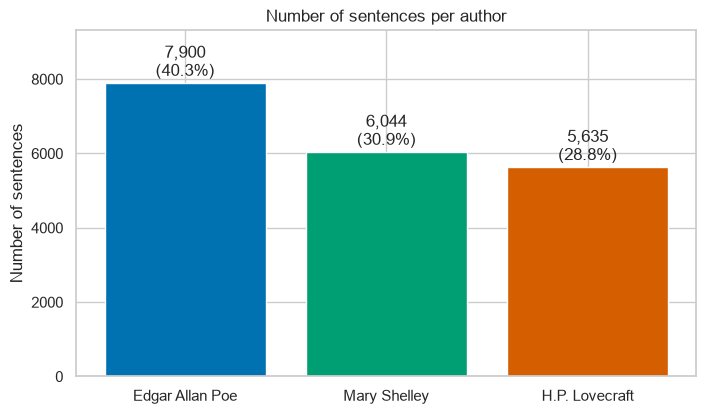

Saved: figures/01_class_balance.png


In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
counts = df["author"].value_counts().reindex(author_order)
bars = ax.bar([author_names[a] for a in author_order], counts.values,
              color=[author_colours[a] for a in author_order])
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 60,
            f"{value:,}\n({value / len(df) * 100:.1f}%)", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.18)
ax.set_ylabel("Number of sentences")
ax.set_title("Number of sentences per author")
save_figure("01_class_balance.png")

This code draws a bar chart of the number of sentences per author, with the count and the percentage written above each bar and each author drawn in their own colour. A picture makes the imbalance easy to judge at a glance. The figure is saved as `figures/01_class_balance.png` for the report.

**What the output shows.** The chart shows the same imbalance as before: Poe is about eleven and a half percentage points larger than Lovecraft. It is a mild imbalance, so the models are judged with macro averages that treat each author equally, and class weights are tested later as a possible fix.

### 4b. Sentence length

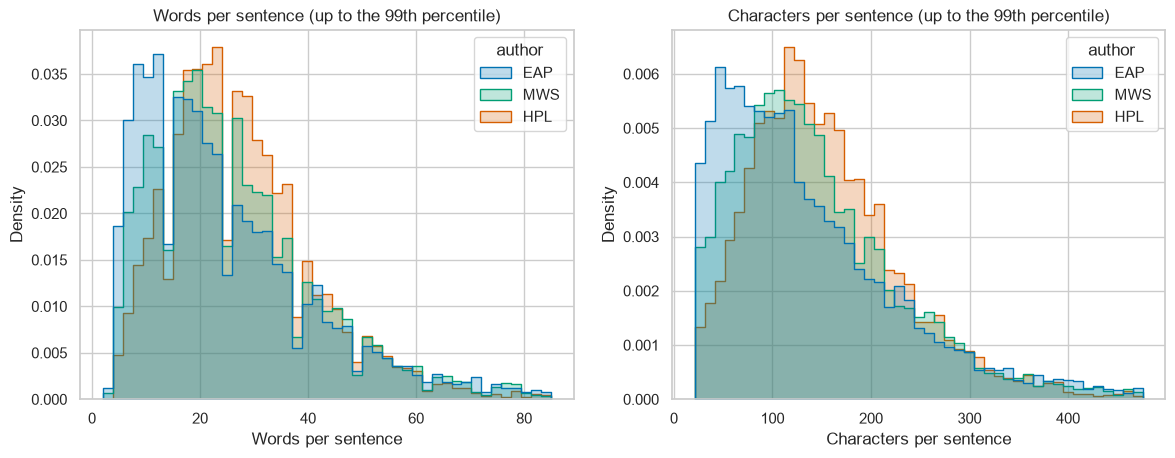

Saved: figures/02_length_histograms.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, column, label in zip(axes, ["word_count", "char_count"], ["Words per sentence", "Characters per sentence"]):
    upper = df[column].quantile(0.99)
    sns.histplot(data=df[df[column] <= upper], x=column, hue="author", hue_order=author_order,
                 palette=author_colours, bins=45, stat="density", common_norm=False,
                 element="step", alpha=0.25, ax=ax)
    ax.set_title(f"{label} (up to the 99th percentile)")
    ax.set_xlabel(label)
save_figure("02_length_histograms.png")

This code draws two histograms, one for the number of words and one for the number of characters in each sentence, with a separate outline for each author. The bars show the share of each author's sentences rather than raw counts, so that an author with more sentences does not look bigger just because of their volume. The very longest one percent of sentences is left out of the picture only, so that a few extreme sentences do not squash the chart. The figure is saved as `figures/02_length_histograms.png`.

**What the output shows.** All three authors have right-skewed length distributions, which means most sentences are short to medium and a few are very long. Lovecraft's distribution is the narrowest and sits slightly to the right of the others, so his sentences are more uniform and a little longer, while Poe's median is the shortest.

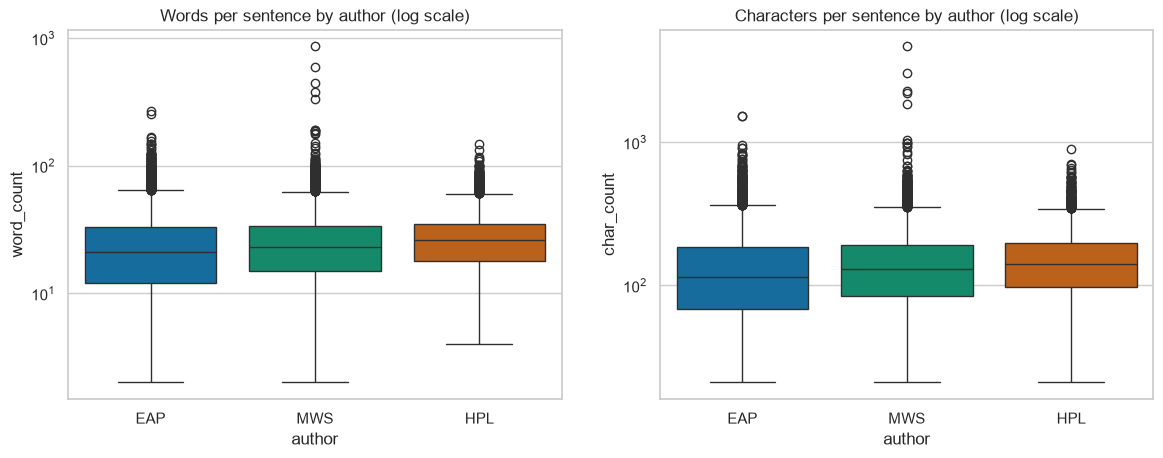

Saved: figures/03_length_boxplots.png


word_count                       char_count                        
             mean median   std min  max       mean median    std min   max
author                                                                    
EAP          25.4   21.0  18.6   2  267      142.2  115.0  105.8  21  1533
MWS          27.4   23.0  23.1   2  861      151.7  130.0  126.3  21  4663
HPL          27.8   26.0  14.1   4  147      155.8  142.0   82.0  21   900

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=df, x="author", y="word_count", order=author_order, hue="author",
            palette=author_colours, legend=False, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Words per sentence by author (log scale)")
sns.boxplot(data=df, x="author", y="char_count", order=author_order, hue="author",
            palette=author_colours, legend=False, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Characters per sentence by author (log scale)")
save_figure("03_length_boxplots.png")

length_summary = df.groupby("author")[["word_count", "char_count"]].agg(["mean", "median", "std", "min", "max"]).round(1)
display(length_summary.loc[author_order])
length_summary.loc[author_order].to_csv(out_dir / "length_summary_by_author.csv")

This code draws a boxplot of sentence length for each author, once for words and once for characters. A boxplot shows the middle half of the sentences as a box, the median as a line, and the unusually long sentences as dots. The vertical axis uses a logarithmic scale because a few sentences are hundreds of words long and would otherwise flatten everything else. Below the charts, a table gives the mean, median, standard deviation, minimum and maximum length for each author. The figure is saved as `figures/03_length_boxplots.png` and the table as a CSV file.

**What the output shows.** The mean and median lengths are close for the three authors, with a median of 21 words for Poe, 23 for Shelley and 26 for Lovecraft. The spread differs more: Lovecraft's standard deviation is 14.1 words and his longest sentence has 147 words, against 18.6 and 267 for Poe and 23.1 and 861 for Shelley. Length gives a small hint about the author but is far from enough on its own, since the boxes overlap heavily.

### 4c. Most common words

In [16]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()
lemma_cache = {}

# Very general words that the NLTK list misses. They are dropped from the lemma view only
# (word clouds and n-grams), because they would otherwise crowd out the more telling words.
extra_eda_stopwords = {"one", "would", "could", "might", "must", "shall", "may", "us", "yet", "even"}


def to_lemma(word):
    if word not in lemma_cache:
        lemma_cache[word] = lemmatizer.lemmatize(word)
    return lemma_cache[word]


# Three EDA-only views of every sentence. None of these is used as model input.
df["tokens"] = df["text"].map(lambda t: [w for w in word_tokenize(t.lower()) if w.isalpha()])
df["tokens_nostop"] = df["tokens"].map(lambda ts: [w for w in ts if w not in stop_words])
df["lemmas"] = df["tokens_nostop"].map(lambda ts: [to_lemma(w) for w in ts if w not in extra_eda_stopwords])

example = df.loc[df["word_count"].between(18, 24)].iloc[0]
print("Original      :", example["text"])
print("Words         :", example["tokens"])
print("No stopwords  :", example["tokens_nostop"])
print("Lemmatised    :", example["lemmas"])
print()
print("NLTK stopword list size:", len(stop_words))

Original      : The astronomer, perhaps, at this point, took refuge in the suggestion of non luminosity; and here analogy was suddenly let fall.
Words         : ['the', 'astronomer', 'perhaps', 'at', 'this', 'point', 'took', 'refuge', 'in', 'the', 'suggestion', 'of', 'non', 'luminosity', 'and', 'here', 'analogy', 'was', 'suddenly', 'let', 'fall']
No stopwords  : ['astronomer', 'perhaps', 'point', 'took', 'refuge', 'suggestion', 'non', 'luminosity', 'analogy', 'suddenly', 'let', 'fall']
Lemmatised    : ['astronomer', 'perhaps', 'point', 'took', 'refuge', 'suggestion', 'non', 'luminosity', 'analogy', 'suddenly', 'let', 'fall']

NLTK stopword list size: 198


This code builds the three cleaned views of every sentence that the word-level EDA needs. First the sentence is lower-cased and split into words, keeping only real alphabetic words so that punctuation and stray pieces are dropped. The second view removes stopwords, which are very common words such as "the" and "of". The third view also drops ten very general words that the NLTK list misses, such as "would", "could" and "us", because without this the word clouds and phrase charts are filled with them, and the lemmatiser wrongly turns "us" into "u". It then lemmatises the remaining words, which means reducing each one to its dictionary form, for example "horrors" becomes "horror", using the WordNet dictionary (Miller, 1995). A small cache makes the lemmatiser fast. One example sentence is printed at each stage so that the effect of each step can be seen. These views are used only for the charts in this section. The model itself later receives the untouched words and punctuation, because the way an author uses small function words is part of their style (Stamatatos, 2009). The lemmatiser used here treats every word as a noun, which is a simple approximation that is good enough for counting.

**What the output shows.** The example shows how the views change the text. Stopwords such as "the", "at" and "and" disappear in the second view, and the lemmatiser leaves the remaining words almost unchanged here because they are already in their base form. The NLTK stopword list has 198 words.

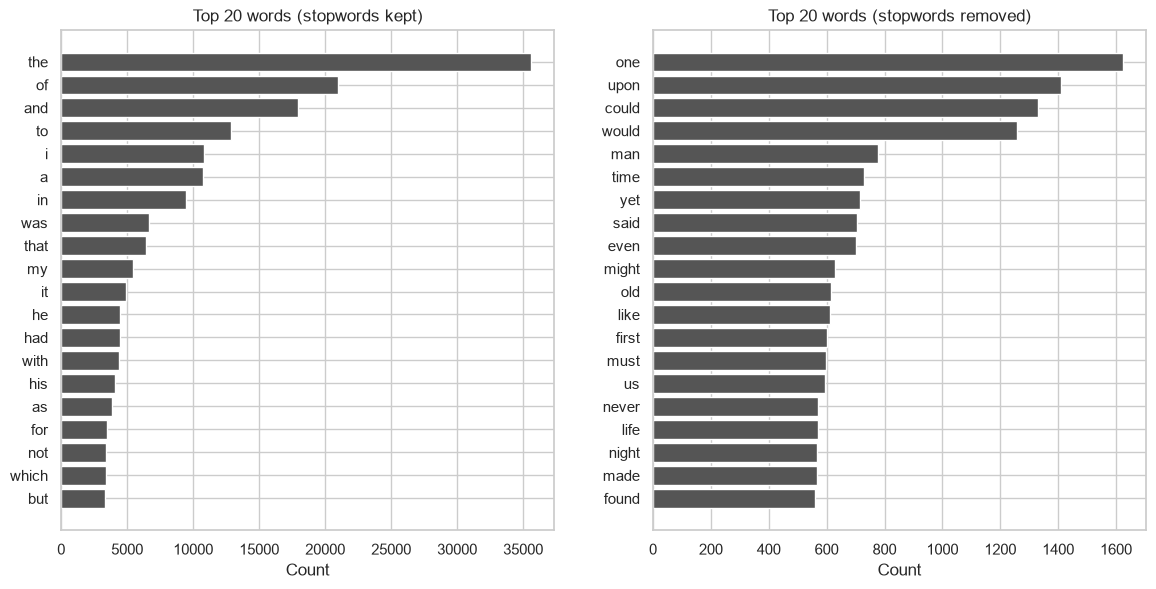

Saved: figures/04_top_words_overall.png


,EAP,MWS,HPL
total words,200295.0,165700.0,156007.0
stopword share (%),52.3,52.5,48.3


In [17]:
def count_words(column, author=None):
    rows = df if author is None else df[df["author"] == author]
    counter = Counter()
    for words in rows[column]:
        counter.update(words)
    return counter


all_counts = {"all": count_words("tokens"), "nostop": count_words("tokens_nostop"), "lemma": count_words("lemmas")}
author_counts = {a: {"all": count_words("tokens", a), "nostop": count_words("tokens_nostop", a),
                     "lemma": count_words("lemmas", a)} for a in author_order}


def bar_top(ax, counter, n, colour, title):
    items = counter.most_common(n)[::-1]
    labels = [" ".join(k) if isinstance(k, tuple) else k for k, _ in items]
    ax.barh(labels, [v for _, v in items], color=colour)
    ax.set_title(title)
    ax.set_xlabel("Count")


fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
bar_top(axes[0], all_counts["all"], 20, "#555555", "Top 20 words (stopwords kept)")
bar_top(axes[1], all_counts["nostop"], 20, "#555555", "Top 20 words (stopwords removed)")
save_figure("04_top_words_overall.png")

share = pd.DataFrame({a: {"total words": sum(author_counts[a]["all"].values()),
                          "stopword share (%)": round(100 * (1 - sum(author_counts[a]["nostop"].values()) /
                                                            sum(author_counts[a]["all"].values())), 1)}
                      for a in author_order})
display(share)

This code counts how often every word appears, first across all sentences and then for each author separately, for the version with stopwords and the version without. It then draws the 20 most common words overall in two panels, one with stopwords kept and one with them removed. With stopwords kept, the list is dominated by small function words such as "the", "of" and "and", which tell us little about topic but a lot about how much each author leans on them. With stopwords removed, the list starts to show content words. A small table underneath gives the total number of words and the share that are stopwords for each author. The chart is saved as `figures/04_top_words_overall.png`.

**What the output shows.** With stopwords kept, the most common words are small function words led by "the", "of" and "and". Between 48 and 53 percent of all words are stopwords, which shows how much of the text would be lost if they were removed: 52.3 percent for Poe, 52.5 percent for Shelley and only 48.3 percent for Lovecraft. Lovecraft therefore has a larger share of content words, which is a first sign of a measurable style difference.

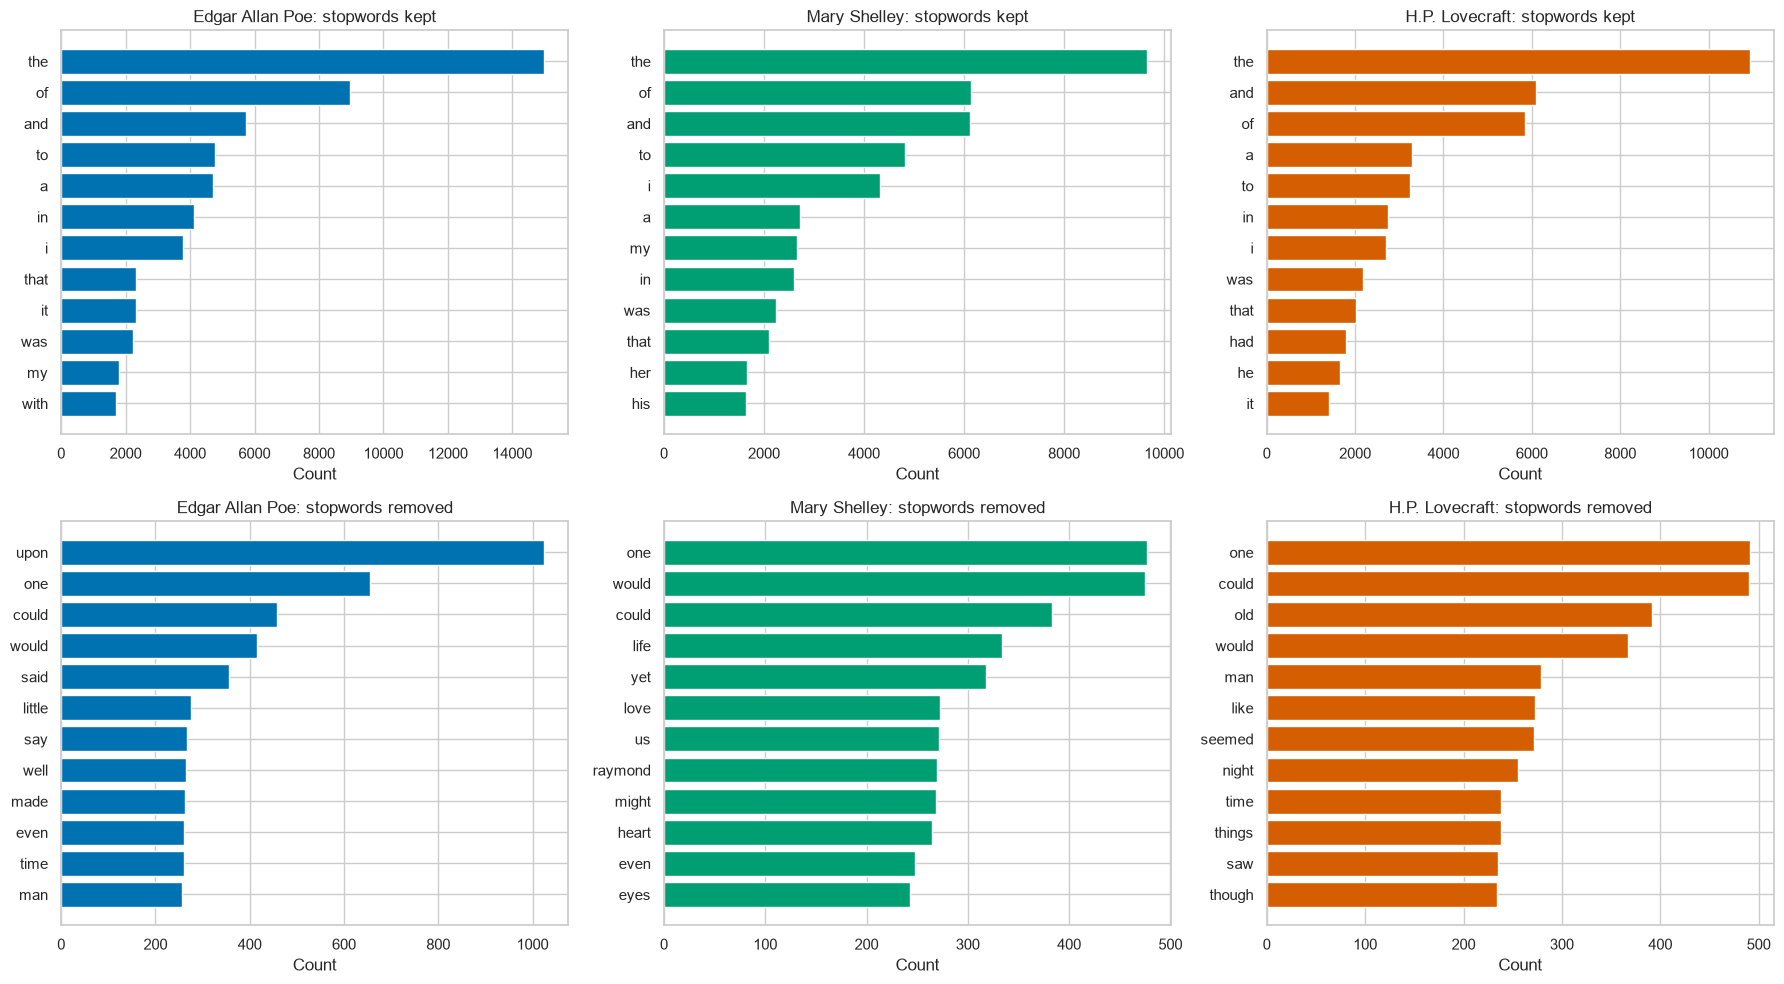

Saved: figures/05_top_words_by_author.png


In [18]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for col, author in enumerate(author_order):
    bar_top(axes[0, col], author_counts[author]["all"], 12, author_colours[author],
            f"{author_names[author]}: stopwords kept")
    bar_top(axes[1, col], author_counts[author]["nostop"], 12, author_colours[author],
            f"{author_names[author]}: stopwords removed")
plt.tight_layout()
save_figure("05_top_words_by_author.png")

This code draws the 12 most common words for each author in a grid of six small charts. The top row keeps stopwords and the bottom row removes them, and each author keeps their own colour. Comparing the columns shows which words each author leans on most, both for small function words and for content words. This is the first look at whether the authors really do use different words, which is the whole basis of the bot. The chart is saved as `figures/05_top_words_by_author.png`.

**What the output shows.** With stopwords kept, "the", "of" and "and" are the top three words for every author, but the balance differs. Poe uses "of" far more often than "and", Lovecraft uses "and" slightly more than "of", and Shelley's list is full of personal words such as "I", "my", "her" and "his". With stopwords removed, Poe stands out for "upon", which he uses about 1,000 times, far more than any other content word (the next, "one", has about 650). Shelley's content words include "life", "love", "heart", "eyes" and the character name "raymond", while Lovecraft's include "old", "night", "seemed", "things" and "saw". These are the kinds of habits a recurrent network can learn.

### 4d. Word clouds

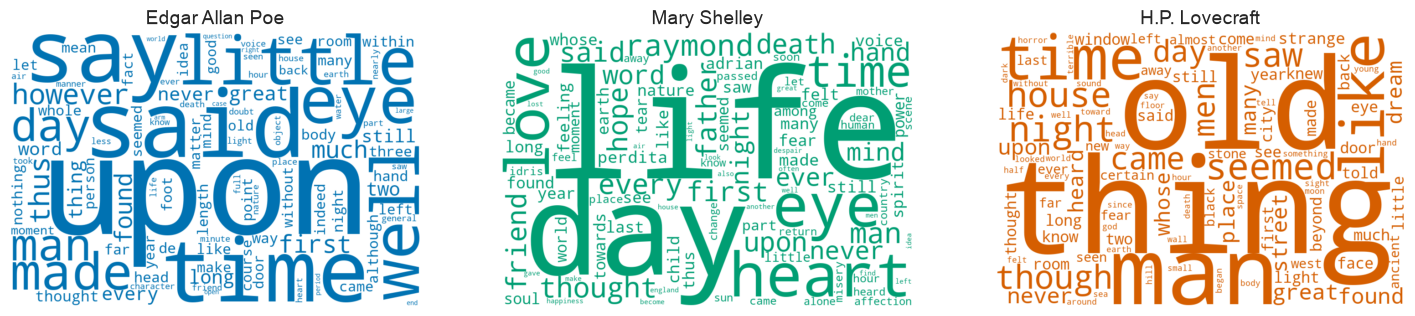

Saved: figures/06_word_clouds.png


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, author in zip(axes, author_order):
    cloud = WordCloud(width=900, height=600, background_color="white", max_words=100,
                      color_func=lambda *args, c=author_colours[author], **kwargs: c,
                      random_state=seed).generate_from_frequencies(author_counts[author]["lemma"])
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(author_names[author], fontsize=14)
    ax.axis("off")
save_figure("06_word_clouds.png")

This code draws one word cloud for each author, using the lemmatised words with stopwords removed. In a word cloud the size of a word shows how often it appears, so the biggest words are the ones the author uses most. The clouds give a quick feel for the subject matter and vocabulary of each author. They are only a visual summary, since the model does not use these cleaned words. The random state is fixed so that the layout is the same every time, and the figure is saved as `figures/06_word_clouds.png`.

**What the output shows.** The clouds match the bar charts. Poe's cloud is led by "upon", "say", "said" and "little". Shelley's is dominated by emotional and personal words such as "life", "love", "heart", "death" and the names "raymond", "perdita" and "adrian". Lovecraft's is led by "old", "thing", "man", "house", "night" and "seemed", which suits his horror themes. Ten very general words were left out of these clouds only, because they filled every cloud equally.

### 4e. Bigrams and trigrams

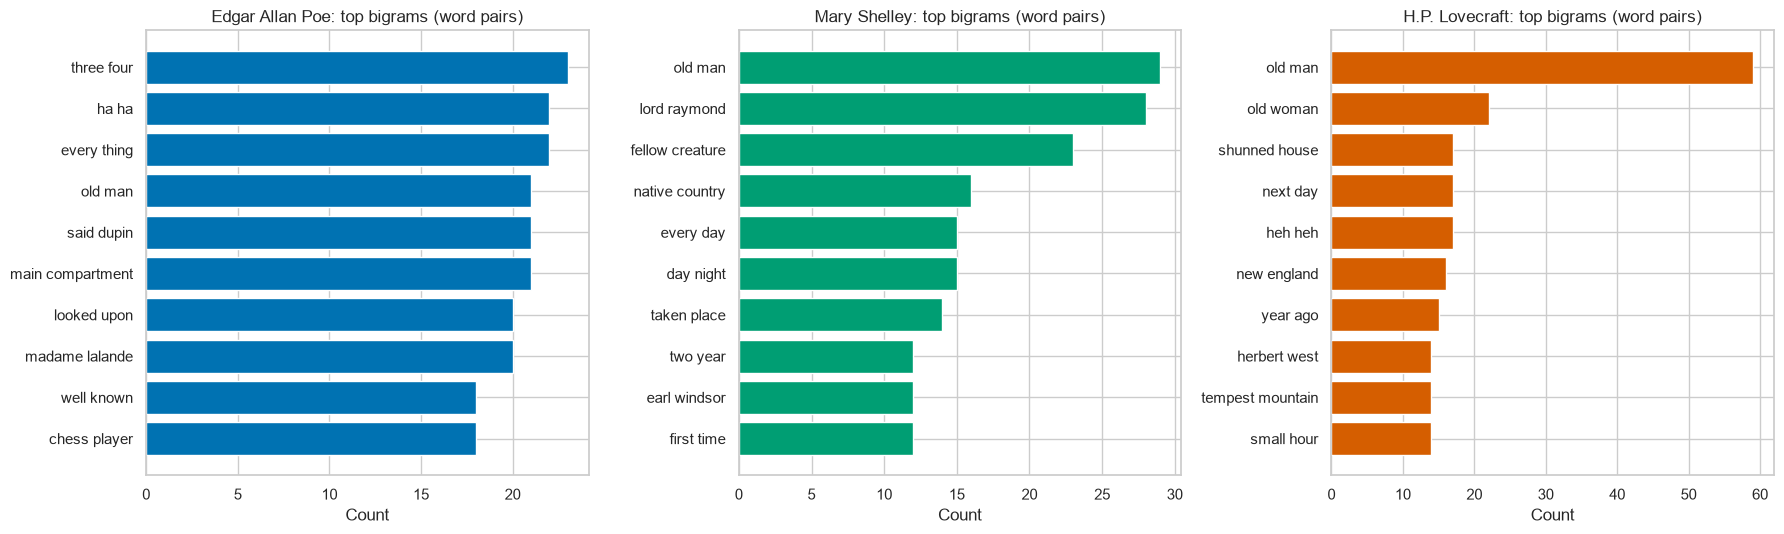

Saved: figures/07_bigrams_by_author.png


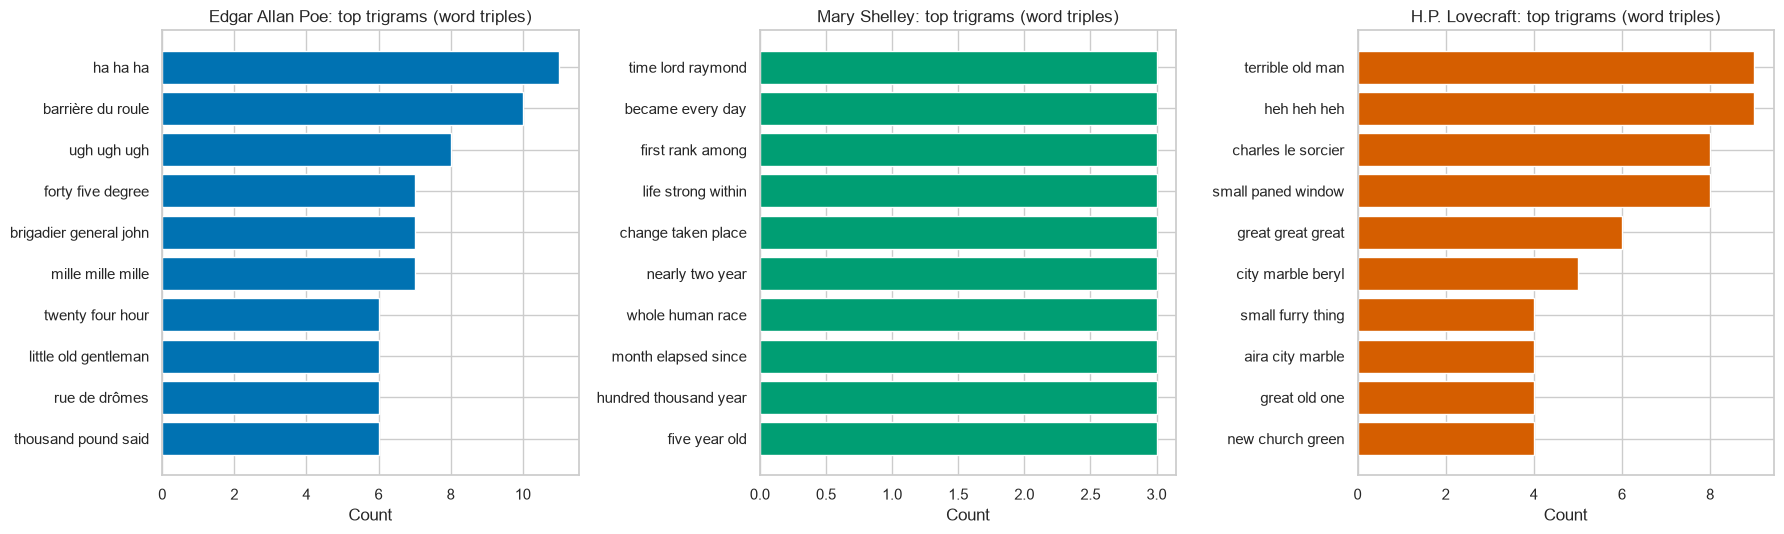

Saved: figures/08_trigrams_by_author.png


In [20]:
def ngram_counter(column, n, author):
    counter = Counter()
    for words in df.loc[df["author"] == author, column]:
        counter.update(zip(*[words[i:] for i in range(n)]))
    return counter


bigrams = {a: ngram_counter("lemmas", 2, a) for a in author_order}
trigrams = {a: ngram_counter("lemmas", 3, a) for a in author_order}

for name, grams, filename in [("bigrams (word pairs)", bigrams, "07_bigrams_by_author.png"),
                              ("trigrams (word triples)", trigrams, "08_trigrams_by_author.png")]:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    for ax, author in zip(axes, author_order):
        bar_top(ax, grams[author], 10, author_colours[author], f"{author_names[author]}: top {name}")
    plt.tight_layout()
    save_figure(filename)

This code finds the most common pairs of words (bigrams) and triples of words (trigrams) for each author, using the lemmatised text with stopwords removed. Looking at short phrases gives more context than single words, because a phrase such as a character's full name or a favourite expression is much more telling than one common word. Each author gets a chart of their ten most frequent phrases, and the charts are saved as `figures/07_bigrams_by_author.png` and `figures/08_trigrams_by_author.png`. Because the stopwords were removed first, the words in a phrase are neighbours in the cleaned text and not always in the original sentence, so the phrases are a guide to topics rather than exact quotations.

**What the output shows.** The word pairs show two different things. Some are style or theme, such as Lovecraft's "old man" (59 uses), "old woman" and "shunned house", and Poe's "ha ha", which turns into "ha ha ha" and "ugh ugh ugh" in the trigrams. Many others are the names of characters and places: "said dupin", "madame lalande" and "chess player" for Poe, "lord raymond" and "earl windsor" for Shelley, and "herbert west", "tempest mountain" and "new england" for Lovecraft. This is an important pitfall, because a network could learn to recognise the story instead of the writing style. Poe's trigrams also include French phrases such as "barrière du roule", which links to the accented letters found in the data quality section. Shelley's top trigrams each occur only three times, which shows that her phrasing is spread over many different combinations.

### 4f. Writing style measurements

In [21]:
df["avg_word_length"] = df["tokens"].map(lambda ts: np.mean([len(w) for w in ts]) if ts else 0)
df["commas"] = df["text"].map(lambda t: t.count(","))
df["semicolons"] = df["text"].map(lambda t: t.count(";"))
df["colons"] = df["text"].map(lambda t: t.count(":"))
df["question_marks"] = df["text"].map(lambda t: t.count("?"))
df["exclamation_marks"] = df["text"].map(lambda t: t.count("!"))
df["double_quotes"] = df["text"].map(lambda t: t.count('"'))
df["apostrophes"] = df["text"].map(lambda t: t.count("'"))
df["stopword_ratio"] = df["tokens"].map(lambda ts: np.mean([w in stop_words for w in ts]) if ts else 0)
df["type_token_ratio"] = df["tokens"].map(lambda ts: len(set(ts)) / len(ts) if ts else 0)

style_features = ["avg_word_length", "commas", "semicolons", "colons", "question_marks",
                  "exclamation_marks", "double_quotes", "apostrophes", "stopword_ratio", "type_token_ratio"]
style_means = df.groupby("author")[style_features].mean().loc[author_order].round(3)
display(style_means.T)
style_means.T.to_csv(out_dir / "stylometric_means_by_author.csv")

# Punctuation per 100 words is fairer than per sentence, because sentence lengths differ.
rate_table = pd.DataFrame({
    a: {m: round(100 * df.loc[df["author"] == a, m].sum() / df.loc[df["author"] == a, "word_count"].sum(), 2)
        for m in ["commas", "semicolons", "colons", "question_marks", "double_quotes", "apostrophes"]}
    for a in author_order})
print("Punctuation marks per 100 words:")
display(rate_table)

author,EAP,MWS,HPL
avg_word_length,4.467,4.440,4.503
commas,2.227,1.993,1.523
semicolons,0.171,0.440,0.203
colons,0.022,0.056,0.008
question_marks,0.065,0.069,0.030
exclamation_marks,0.000,0.000,0.000
double_quotes,0.378,0.243,0.091
apostrophes,0.169,0.079,0.303
stopword_ratio,0.520,0.523,0.485
type_token_ratio,0.890,0.886,0.891


Punctuation marks per 100 words:


,EAP,MWS,HPL
commas,8.75,7.27,5.48
semicolons,0.67,1.61,0.73
colons,0.09,0.20,0.03
question_marks,0.25,0.25,0.11
double_quotes,1.49,0.89,0.33
apostrophes,0.66,0.29,1.09


This code measures ten simple writing style features for every sentence, which is the classic approach to authorship analysis known as stylometry (Stamatatos, 2009). These are the average word length, the number of commas, semicolons, colons, question marks, exclamation marks, double quotation marks and apostrophes, the share of words that are stopwords, and the type-token ratio, which is the number of different words divided by the total number of words and is a simple measure of how varied the vocabulary is. The table shows the average of each feature for each author. Because sentences differ in length, a second table shows how many of each punctuation mark there are per 100 words, which is a fairer comparison between authors. Note that the type-token ratio is naturally higher for short sentences, so it should be read together with the length results. The first table is saved as a CSV file in the `outputs` folder.

**What the output shows.** The averages show clear habits. Per 100 words, Poe writes 8.75 commas, Shelley 7.27 and Lovecraft 5.48. Shelley uses 1.61 semicolons per 100 words, more than twice Poe's 0.67 and Lovecraft's 0.73, and her colon rate of 0.20 is also the highest. Poe uses the most double quotation marks (1.49 per 100 words against 0.89 for Shelley and 0.33 for Lovecraft), while Lovecraft uses the most apostrophes (1.09 per 100 words against 0.66 for Poe and 0.29 for Shelley), which probably reflects contractions in dialogue, although this was not checked. Lovecraft's stopword ratio is lower at 0.485 against about 0.52 for the others. Average word length (about 4.4 to 4.5 letters) and type-token ratio (about 0.89) are almost identical, and exclamation marks are zero for everyone.

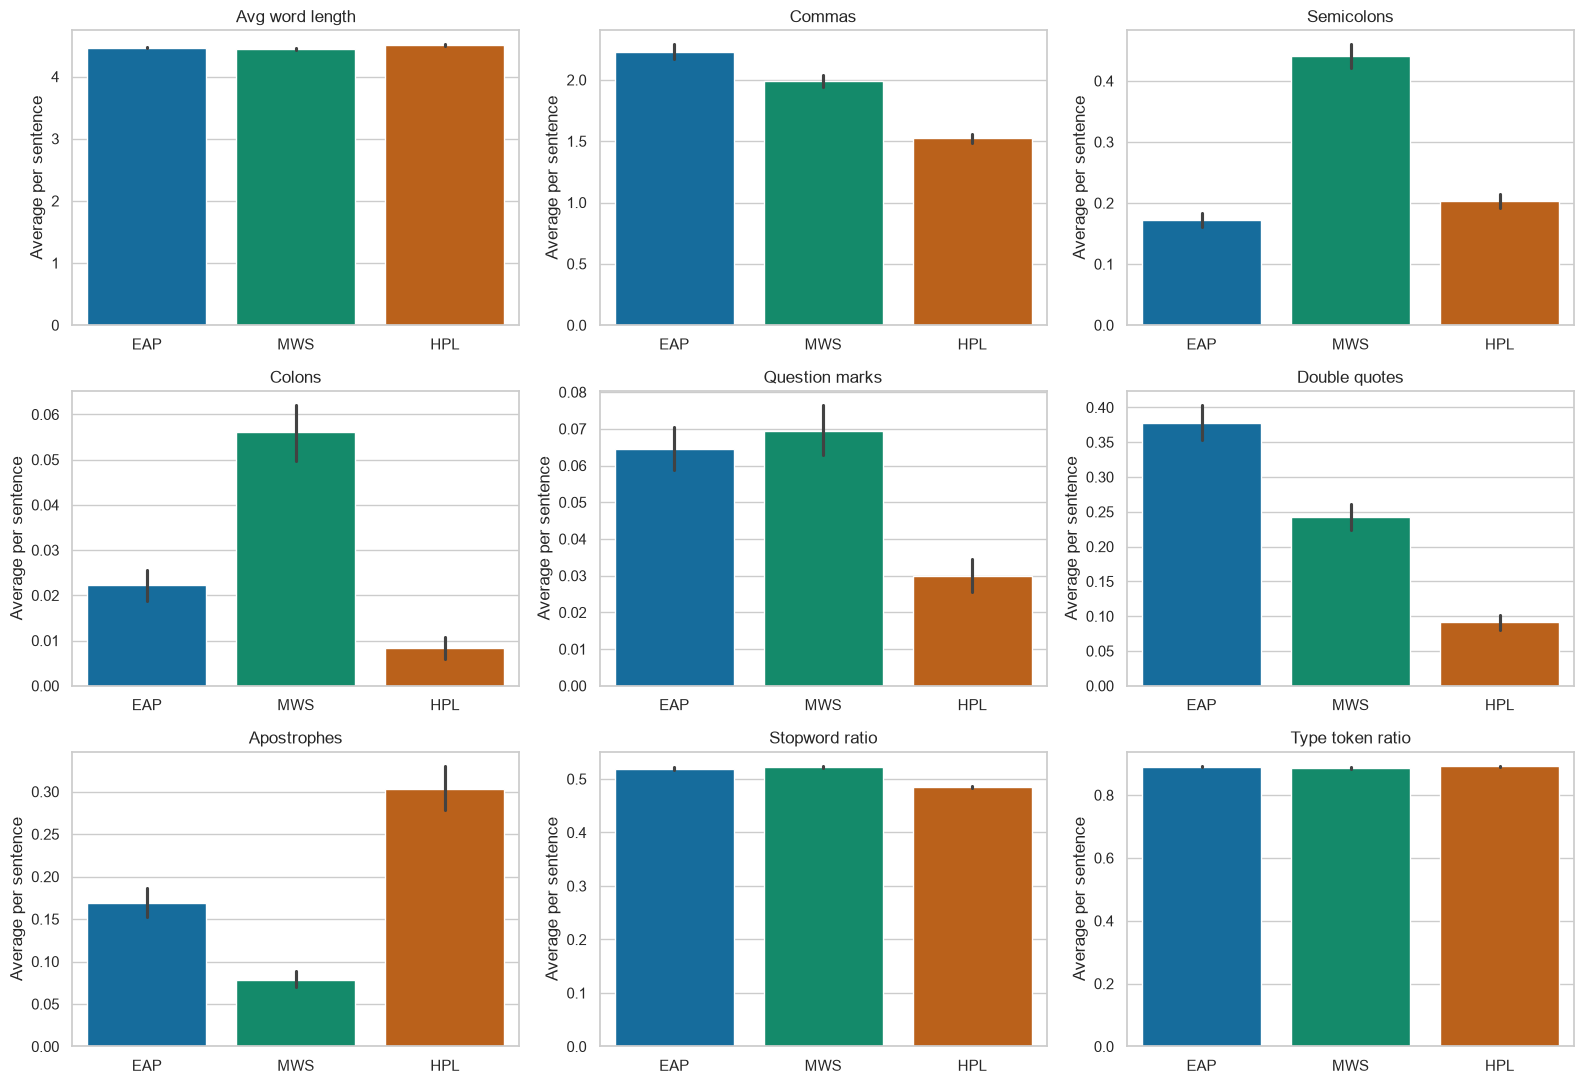

Saved: figures/09_stylometric_features.png


,H,p_value,effect_size
feature,,,
semicolons,801.9,7.6e-175,0.0410
stopword_ratio,752.1,4.9e-164,0.0384
double_quotes,400.4,1.1e-87,0.0205
apostrophes,335.8,1.2e-73,0.0172
colons,220.7,1.2e-48,0.0113
commas,147.2,1.1e-32,0.0075
question_marks,91.1,1.7e-20,0.0047
avg_word_length,51.1,8.0e-12,0.0026
type_token_ratio,24.0,6.3e-06,0.0012


In [22]:
plot_features = [f for f in style_features if df[f].nunique() > 1]     # skip features that are always zero
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, feature in zip(axes.ravel(), plot_features):
    sns.barplot(data=df, x="author", y=feature, order=author_order, hue="author",
                palette=author_colours, legend=False, errorbar=("ci", 95), ax=ax)
    ax.set_title(feature.replace("_", " ").capitalize())
    ax.set_xlabel("")
    ax.set_ylabel("Average per sentence")
for ax in axes.ravel()[len(plot_features):]:
    ax.axis("off")
plt.tight_layout()
save_figure("09_stylometric_features.png")

# Do the authors really differ? Kruskal-Wallis test (Kruskal and Wallis, 1952), with an effect size.
rows = []
n_total = len(df)
for feature in style_features:
    groups = [df.loc[df["author"] == a, feature] for a in author_order]
    if df[feature].nunique() <= 1:
        rows.append([feature, np.nan, np.nan, np.nan])
        continue
    h_stat, p_value = stats.kruskal(*groups)
    rows.append([feature, h_stat, p_value, h_stat / (n_total - 1)])       # epsilon squared effect size
tests = pd.DataFrame(rows, columns=["feature", "H", "p_value", "effect_size"]).set_index("feature")
tests_view = tests.sort_values("effect_size", ascending=False)
display(tests_view.assign(H=tests_view["H"].round(1), p_value=tests_view["p_value"].map(lambda p: f"{p:.1e}"),
                          effect_size=tests_view["effect_size"].round(4)))
tests.to_csv(out_dir / "stylometric_tests.csv")

This code draws a small bar chart for each style feature, showing the average per sentence for each author with a 95 percent confidence interval as the thin line on top. The exclamation mark feature is left out of the chart because it is zero for every sentence, as found in the data quality section. The second half of the code asks whether the differences between the authors are real or just chance. It runs a Kruskal-Wallis test for each feature, which compares the three authors without assuming that the data follows a bell curve (Kruskal and Wallis, 1952). Each test gives a p-value, where a small value means the differences are unlikely to be chance. With almost 20 000 sentences even tiny differences give tiny p-values, so the code also reports an effect size, which measures how large the difference is, from 0 for no difference upwards. The chart is saved as `figures/09_stylometric_features.png` and the test table as a CSV file.

**What the output shows.** All differences except the always-zero exclamation feature are statistically significant, with every p-value below 0.0001. The effect sizes are more telling. They are all small, and the largest are semicolons (0.041) and the stopword ratio (0.038), followed by double quotation marks (0.021), apostrophes (0.017), colons (0.011) and commas (0.008). Average word length (0.003) and type-token ratio (0.001) barely differ between authors. The lesson is that no single feature identifies an author, so a model has to combine many small habits, which is what a recurrent network reading the whole sentence can do. This also supports keeping the punctuation and the stopwords, because the strongest features are exactly these.

### 4g. Vocabulary size and overlap between authors

,total words,different words,words used 5+ times,"different words in a random 156,007-word sample",words only this author uses,words only this author uses (5+ times)
EAP,200295,15246,4044,13712,5684,379
MWS,165700,11519,3423,11240,2961,178
HPL,156007,14436,3670,14436,5515,487


Words used by all three authors: 5367
Words in the whole dataset     : 24997


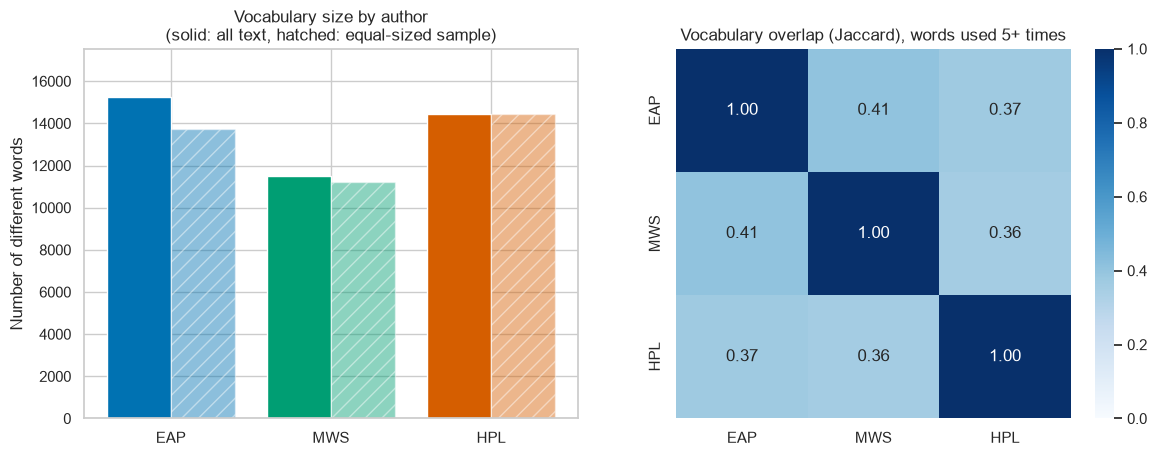

Saved: figures/10_vocabulary_size_overlap.png


In [23]:
author_tokens = {a: [w for ts in df.loc[df["author"] == a, "tokens"] for w in ts] for a in author_order}
vocab = {a: set(author_tokens[a]) for a in author_order}
vocab_common = {a: {w for w, n in Counter(author_tokens[a]).items() if n >= 5} for a in author_order}

# Vocabulary size depends on how much text an author has, so also compare equal-sized random samples.
rng = np.random.default_rng(seed)
sample_size = min(len(t) for t in author_tokens.values())
equal_sample_types = {a: len(set(rng.choice(np.array(author_tokens[a]), sample_size, replace=False)))
                      for a in author_order}

vocab_table = pd.DataFrame({
    "total words": {a: len(author_tokens[a]) for a in author_order},
    "different words": {a: len(vocab[a]) for a in author_order},
    "words used 5+ times": {a: len(vocab_common[a]) for a in author_order},
    f"different words in a random {sample_size:,}-word sample": equal_sample_types,
    "words only this author uses": {a: len(vocab[a] - set().union(*[vocab[b] for b in author_order if b != a]))
                                    for a in author_order},
    "words only this author uses (5+ times)": {a: len(vocab_common[a] - set().union(*[vocab[b] for b in author_order if b != a]))
                                                for a in author_order},
})
display(vocab_table)
print("Words used by all three authors:", len(set.intersection(*vocab.values())))
print("Words in the whole dataset     :", len(set.union(*vocab.values())))


def jaccard(a, b):
    return len(a & b) / len(a | b)


overlap = pd.DataFrame([[jaccard(vocab_common[a], vocab_common[b]) for b in author_order] for a in author_order],
                       index=author_order, columns=author_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
positions = np.arange(len(author_order))
axes[0].bar(positions - 0.2, [len(vocab[a]) for a in author_order], width=0.4,
            color=[author_colours[a] for a in author_order])
axes[0].bar(positions + 0.2, [equal_sample_types[a] for a in author_order], width=0.4,
            color=[author_colours[a] for a in author_order], alpha=0.45, hatch="//", edgecolor="white")
axes[0].set_xticks(positions)
axes[0].set_xticklabels(author_order)
axes[0].set_ylim(0, max(len(v) for v in vocab.values()) * 1.15)
axes[0].set_title("Vocabulary size by author\n(solid: all text, hatched: equal-sized sample)")
axes[0].set_ylabel("Number of different words")
sns.heatmap(overlap, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Vocabulary overlap (Jaccard), words used 5+ times")
save_figure("10_vocabulary_size_overlap.png")
vocab_table.to_csv(out_dir / "vocabulary_by_author.csv")

This code compares the vocabularies of the three authors. For each author it counts the total words, the number of different words, the number of words used at least five times, and the number of words that only that author uses. Since an author with more sentences will naturally show more different words, it also draws a random sample of the same size from each author and counts the different words in that fair sample. It then measures how much the vocabularies overlap using the Jaccard score, which is the number of words two authors share divided by the number of words either of them uses, so 1 means identical vocabularies and 0 means nothing in common. The overlap is calculated only on words used at least five times, so that one-off spellings and rare names do not distort it. The left chart shows vocabulary sizes and the right chart shows the overlap. The figure is saved as `figures/10_vocabulary_size_overlap.png` and the table as a CSV file.

**What the output shows.** Poe has the largest vocabulary with 15,246 different words, then Lovecraft with 14,436 and Shelley with 11,519. Poe also wrote the most text, so the fair comparison uses equal-sized samples of 156,007 words. In that comparison Lovecraft has the richest vocabulary (14,436 different words against 13,712 for Poe and 11,240 for Shelley), and Shelley's vocabulary is the smallest. Only 5,367 of the 24,997 words in the whole dataset are used by all three authors. The Jaccard scores show that only about four in every ten frequent words are shared: 0.41 between Poe and Shelley, 0.37 between Poe and Lovecraft and 0.36 between Shelley and Lovecraft. The authors overlap enough to be confusable but differ enough for their word choice to be useful, especially since each has hundreds of frequent words that the others never use (379 for Poe, 178 for Shelley and 487 for Lovecraft).

## 5. Preparing the text for the model and splitting the data

From this point on the notebook prepares data for the neural networks. The most important rule of this part is that anything that learns from the data, such as the word list the model will know, must learn from the training sentences only. Otherwise information from the test sentences leaks into the model and the test score is unfairly high. For that reason the data is split first, before any word list is built.

In [24]:
def clean_for_model(text):
    """Light cleaning that keeps stopwords and the punctuation that carries style."""
    text = text.lower()
    text = text.replace("\u2019", "'").replace("\u2018", "'").replace("\u201c", '"').replace("\u201d", '"')
    text = text.replace(".", " ")                                  # full stops only mark the sentence end
    text = re.sub(r'([,;:?!"()\-\u2014\u2013])', r" \1 ", text)     # each mark becomes its own token
    text = re.sub(r"(?<!\w)'|'(?!\w)", " ' ", text)                # quote marks, but keep "don't" whole
    return re.sub(r"\s+", " ", text).strip()


df["model_text"] = df["text"].map(clean_for_model)

for i in [0, 3, 6]:
    print("Original:", df.loc[i, "text"])
    print("Cleaned :", df.loc[i, "model_text"])
    print()
print("Shortest cleaned sentence (tokens):", df["model_text"].str.split().str.len().min())

Original: This process, however, afforded me no means of ascertaining the dimensions of my dungeon; as I might make its circuit, and return to the point whence I set out, without being aware of the fact; so perfectly uniform seemed the wall.
Cleaned : this process , however , afforded me no means of ascertaining the dimensions of my dungeon ; as i might make its circuit , and return to the point whence i set out , without being aware of the fact ; so perfectly uniform seemed the wall

Original: How lovely is spring As we looked from Windsor Terrace on the sixteen fertile counties spread beneath, speckled by happy cottages and wealthier towns, all looked as in former years, heart cheering and fair.
Cleaned : how lovely is spring as we looked from windsor terrace on the sixteen fertile counties spread beneath , speckled by happy cottages and wealthier towns , all looked as in former years , heart cheering and fair

Original: The astronomer, perhaps, at this point, took refuge in the sugg

This code defines and applies the cleaning step for the model input. The cleaning is deliberately light. The text is made lower case, curly quotation marks are turned into plain ones, and full stops are removed because they mostly just mark the end of a sentence. Every comma, semicolon, colon, question mark, quotation mark and apostrophe used as a quote is then separated from its neighbouring word by spaces, so that the network sees each one as its own token that it can learn from. Apostrophes inside words, as in "don't", stay attached. Nothing else is removed. In particular the stopwords are kept and the words are not lemmatised, because how often an author uses words like "the", "of" and "upon", and how they punctuate, is a large part of their style, whereas topic words are less reliable. Three examples show the original and the cleaned text side by side, and the last line checks that no sentence has become empty. This is a fixed rule applied to each sentence on its own, so it cannot leak information between the training and test sets.

In [25]:
label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["author"])
class_names = list(label_encoder.classes_)
for number, author in enumerate(class_names):
    print(number, "=", author, f"({author_names[author]})")

0 = EAP (Edgar Allan Poe)
1 = HPL (H.P. Lovecraft)
2 = MWS (Mary Shelley)


This code turns the author labels into numbers, because a neural network can only work with numbers. The label encoder gives each author a whole number in alphabetical order, and the printout shows which number belongs to which author. This numbering is used in every later table and confusion matrix, so the order of the authors in those tables (EAP, HPL, MWS) follows this mapping and not the order used in the earlier charts.

**What the output shows.** The mapping is 0 for Poe (EAP), 1 for Lovecraft (HPL) and 2 for Shelley (MWS).

In [26]:
x = df["model_text"]
y = df["label"]

# 70 percent for training and validation together, 30 percent for the final test.
text_train, text_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, random_state=seed, stratify=y)
# Then 20 percent of the training part is set aside as the validation set.
text_train, text_val, y_train, y_val = train_test_split(
    text_train, y_train, test_size=0.2, random_state=seed, stratify=y_train)

split_table = pd.DataFrame({
    "sentences": [len(y_train), len(y_val), len(y_test)],
    **{a: [round((s == i).mean() * 100, 1) for s in (y_train, y_val, y_test)]
       for i, a in enumerate(class_names)},
}, index=["train", "validation", "test"])
split_table.columns = ["sentences"] + [f"{a} (%)" for a in class_names]
display(split_table)
print("Total:", len(y_train) + len(y_val) + len(y_test))
y_train, y_val, y_test = y_train.to_numpy(), y_val.to_numpy(), y_test.to_numpy()

,sentences,EAP (%),HPL (%),MWS (%)
train,10964,40.4,28.8,30.9
validation,2741,40.4,28.8,30.9
test,5874,40.3,28.8,30.9


Total: 19579


This code splits the sentences into three separate sets. First 30 percent of all sentences are put aside as the test set, which stays untouched until the final evaluation. Of the remaining 70 percent, one fifth becomes the validation set, which is used while training to watch for overfitting and to compare settings, and the rest is the training set the model actually learns from. The split is stratified, which means every set keeps the same mix of authors as the whole dataset, and it uses the fixed seed so that the split is the same on every run. The table proves this by showing the size of each set and the percentage of each author in it, and the counts add up to the full dataset.

**What the output shows.** The training set has 10,964 sentences, the validation set 2,741 and the test set 5,874, which adds up to all 19,579. Every author's share stays within about a tenth of a percentage point of the full dataset in each set, so the split is properly stratified.

## 6. Feature selection and choosing the model settings from the data

Feature selection here means deciding what the model is allowed to see and how much of it. This section makes four decisions using only the training set: how long a sentence the model will read, how many different words it will know, which punctuation and words carry the most author information, and what to keep in the input. Each decision is tied to a chart or a table, and the decisions are summarised at the end of the section.

### 6a. How long a sentence should the model read?

,tokens
count,10964.0
mean,29.3
std,21.9
min,2.0
50%,25.0
90%,52.0
95%,64.0
99%,95.0
max,875.0


Chosen maxlen (95th percentile of training lengths): 64
Share of training sentences longer than maxlen: 4.9%
Share of all training tokens that would be cut: 4.0%


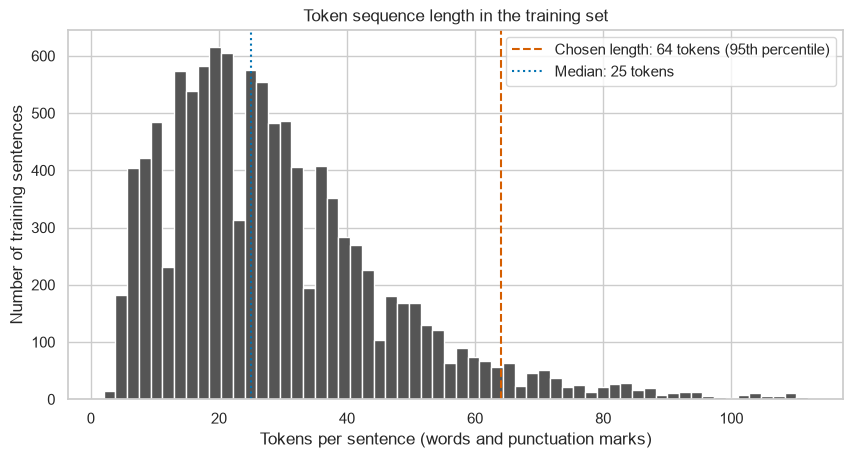

Saved: figures/11_sequence_length_distribution.png


In [27]:
probe_tokenizer = Tokenizer(oov_token="<OOV>", filters="", lower=True)   # exploration only, fitted on training text
probe_tokenizer.fit_on_texts(text_train)
train_lengths = np.array([len(seq) for seq in probe_tokenizer.texts_to_sequences(text_train)])

display(pd.Series(train_lengths).describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1).to_frame("tokens"))

maxlen = int(np.ceil(np.percentile(train_lengths, 95)))
print("Chosen maxlen (95th percentile of training lengths):", maxlen)
print(f"Share of training sentences longer than maxlen: {(train_lengths > maxlen).mean() * 100:.1f}%")
print(f"Share of all training tokens that would be cut: {np.clip(train_lengths - maxlen, 0, None).sum() / train_lengths.sum() * 100:.1f}%")

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.hist(train_lengths[train_lengths <= np.percentile(train_lengths, 99.5)], bins=60, color="#555555")
ax.axvline(maxlen, color="#D55E00", linestyle="--", label=f"Chosen length: {maxlen} tokens (95th percentile)")
ax.axvline(np.median(train_lengths), color="#0072B2", linestyle=":", label=f"Median: {int(np.median(train_lengths))} tokens")
ax.set_xlabel("Tokens per sentence (words and punctuation marks)")
ax.set_ylabel("Number of training sentences")
ax.set_title("Token sequence length in the training set")
ax.legend()
save_figure("11_sequence_length_distribution.png")

This code decides how many tokens the model will read from each sentence. A recurrent network needs every input to be the same length, so short sentences are padded with blanks and long ones are cut. If the chosen length is too short, useful text is thrown away. If it is too long, most of every sentence is padding, training is slower, and the few giant sentences decide the size for everyone. The code turns each training sentence into a sequence of token numbers, counts how many tokens each one has, and prints the usual summary statistics. It then picks the 95th percentile as the length, which means 95 out of every 100 sentences fit completely, and it reports how many sentences and how many tokens would be cut off. The histogram marks the chosen length and the median. This exploratory word list is fitted on the training sentences only. The figure is saved as `figures/11_sequence_length_distribution.png`.

**What the output shows.** In the training set a sentence has a median of 25 tokens, which count words and punctuation marks, and the 95th percentile is 64 tokens. The maximum is 875 tokens, a single extreme sentence. The chosen length of 64 keeps 95.1 percent of sentences whole. Only 4.9 percent of the sentences are cut, and cutting them removes just 4.0 percent of all the tokens. A length near the maximum would have made almost every input mostly padding for the sake of one sentence.

### 6b. How many different words should the model know?

Different tokens in the training set: 20346
Tokens seen only once: 8379 (41% of the word list)
Chosen num_words: 11969


,num_words,training tokens covered (%),validation tokens covered (%)
0,1000,76.3,76.5
1,2000,82.7,82.7
2,3000,86.5,86.2
3,5000,91.0,90.2
4,8000,94.7,93.3
5,11969,97.4,95.5
6,15000,98.3,96.1
7,20348,100.0,97.4


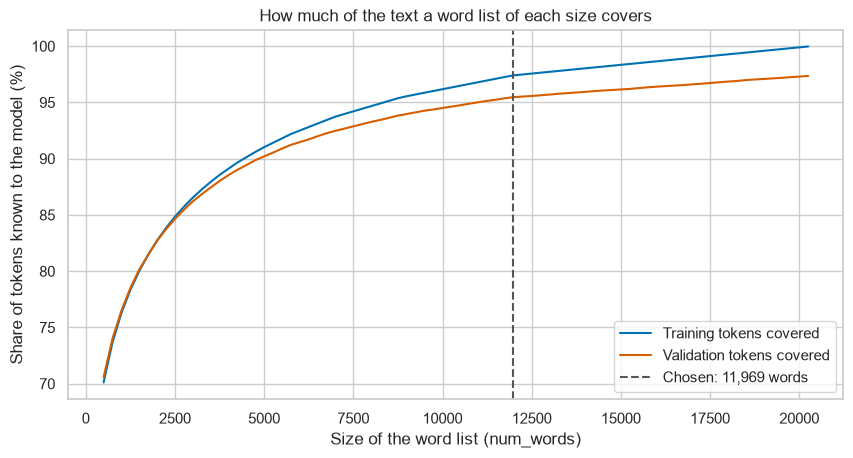

Saved: figures/12_vocabulary_coverage.png


In [28]:
word_counts = pd.Series(probe_tokenizer.word_counts).sort_values(ascending=False)   # training word frequencies
total_tokens = word_counts.sum()
print("Different tokens in the training set:", len(word_counts))
print("Tokens seen only once:", (word_counts == 1).sum(), f"({(word_counts == 1).mean() * 100:.0f}% of the word list)")

# A word list of size N keeps the N-2 most common tokens (index 0 is padding and index 1 is <OOV>).
val_indices = np.concatenate(probe_tokenizer.texts_to_sequences(text_val))


def coverage(n):
    kept = n - 2
    train_cov = word_counts.iloc[:kept].sum() / total_tokens
    val_cov = np.mean((val_indices < n) & (val_indices != 1))
    return train_cov * 100, val_cov * 100


# Rule: a word seen only once in training gives the network nothing to learn from,
# so the model only learns words seen at least twice. All other words become <OOV>.
num_words = int((word_counts >= 2).sum()) + 2
print("Chosen num_words:", num_words)

sizes = sorted({1000, 2000, 3000, 5000, 8000, num_words, 15000, len(word_counts) + 2})
coverage_table = pd.DataFrame([(n, *coverage(n)) for n in sizes],
                              columns=["num_words", "training tokens covered (%)", "validation tokens covered (%)"]).round(1)
display(coverage_table)

grid = np.arange(500, len(word_counts) + 2, 250)
curve = np.array([coverage(n) for n in grid])
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(grid, curve[:, 0], label="Training tokens covered", color="#0072B2")
ax.plot(grid, curve[:, 1], label="Validation tokens covered", color="#D55E00")
ax.axvline(num_words, color="#555555", linestyle="--", label=f"Chosen: {num_words:,} words")
ax.set_xlabel("Size of the word list (num_words)")
ax.set_ylabel("Share of tokens known to the model (%)")
ax.set_title("How much of the text a word list of each size covers")
ax.legend(loc="lower right")
save_figure("12_vocabulary_coverage.png")

This code decides how many different words the model will know. Each known word gets its own row in the embedding layer of the network, which is a lookup table of numbers describing each word, so a bigger word list means a bigger and more overfit-prone model. Any word outside the list is replaced by a single special "unknown" token called OOV, which stands for out of vocabulary. The code first counts how often every token appears in the training set and finds that a large share of the words appear only once. It applies a simple rule: a word seen only once cannot teach the network anything reliable, so only words seen at least twice are kept. The table and chart then check how much of the text this list covers, both in the training sentences and in the validation sentences, which the list has never seen. The figure is saved as `figures/12_vocabulary_coverage.png`.

**What the output shows.** The training set has 20,346 different tokens, and 8,379 of them (41 percent) appear only once. Keeping only tokens seen at least twice gives a word list of 11,969, which covers 97.4 percent of the training tokens and 95.5 percent of the validation tokens. The curve flattens quickly. Going from 12,000 to the full list of 20,000 words would add only about two more percentage points on validation, while adding thousands of words that are seen just once. In the test set, 4.8 percent of tokens end up as unknown, which is the price of the smaller word list.

### 6c. Which words and punctuation marks separate the authors?

Words tested (used 5+ times in training): 5675
Words with p below the Bonferroni limit : 498


,word,chi2,p_value,count
0,her,1179.4,7.7e-257,1304
1,she,638.2,2.6e-139,739
2,my,507.1,7.6e-111,3026
3,you,411.0,5.7e-90,1133
4,upon,335.9,1.1e-73,814
5,is,309.0,7.9e-68,1519
6,love,280.6,1.2e-61,197
7,and,277.3,6.2e-61,9971
8,your,269.4,3.2e-59,402
9,raymond,269.4,3.2e-59,126


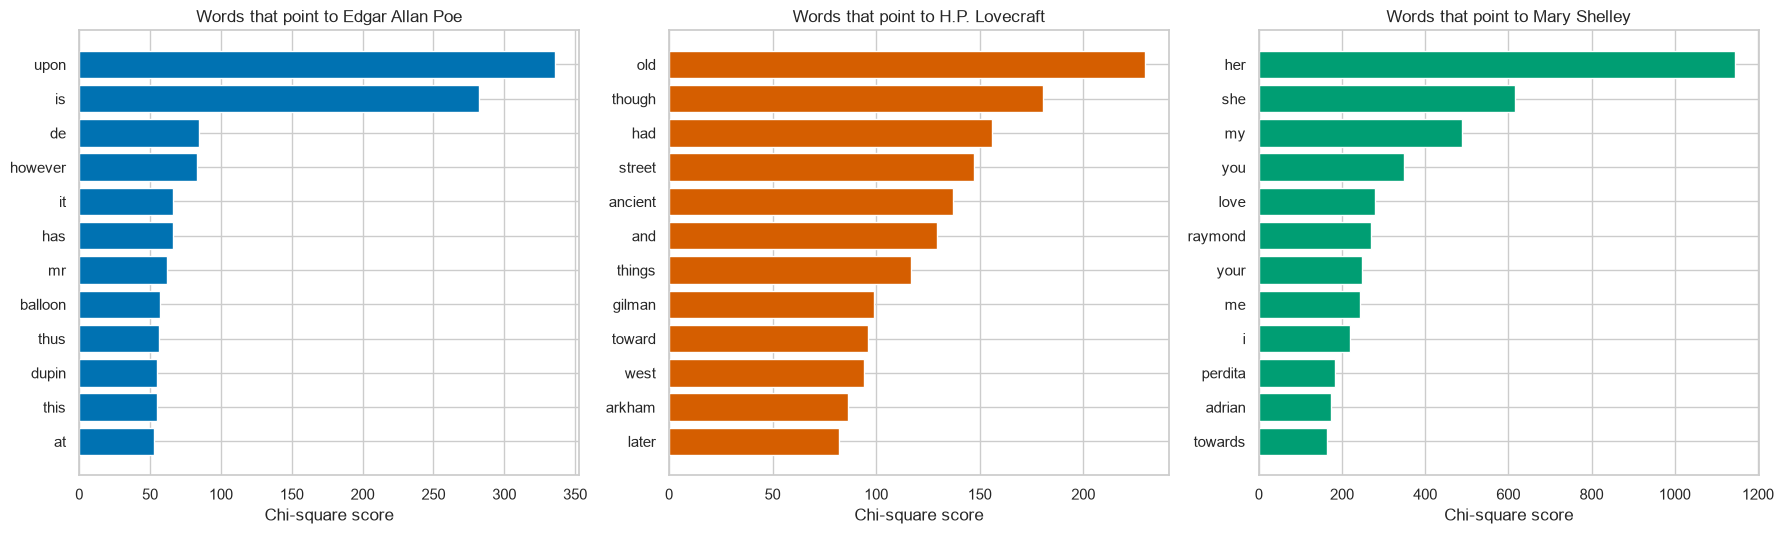

Saved: figures/13_chi_square_words.png


In [29]:
word_vectoriser = CountVectorizer(lowercase=False, token_pattern=r"[^\W\d_]+(?:'[^\W\d_]+)*", min_df=5)
x_words = word_vectoriser.fit_transform(text_train)
words = np.array(word_vectoriser.get_feature_names_out())
word_totals = np.asarray(x_words.sum(axis=0)).ravel()

chi_scores, chi_p = chi2(x_words, y_train)
chi_table = pd.DataFrame({"word": words, "chi2": chi_scores, "p_value": chi_p, "count": word_totals})
bonferroni = 0.05 / len(chi_table)
print("Words tested (used 5+ times in training):", len(chi_table))
print("Words with p below the Bonferroni limit :", (chi_table["p_value"] < bonferroni).sum())
display(chi_table.nlargest(15, "chi2").assign(p_value=lambda t: t["p_value"].map(lambda p: f"{p:.1e}")).round(1).reset_index(drop=True))

# Which author does each top word point to? One-versus-rest chi-square for each author.
top_by_author = {}
for i, author in enumerate(class_names):
    scores, _ = chi2(x_words, (y_train == i).astype(int))
    in_class = np.asarray(x_words[y_train == i].sum(axis=0)).ravel()
    over_used = in_class / word_totals > in_class.sum() / word_totals.sum()      # used more than their share
    frame = pd.DataFrame({"word": words, "chi2": scores, "count": word_totals})[over_used]
    top_by_author[author] = frame.nlargest(12, "chi2")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, author in zip(axes, class_names):
    top = top_by_author[author][::-1]
    ax.barh(top["word"], top["chi2"], color=author_colours[author])
    ax.set_title(f"Words that point to {author_names[author]}")
    ax.set_xlabel("Chi-square score")
plt.tight_layout()
save_figure("13_chi_square_words.png")
chi_table.nlargest(200, "chi2").to_csv(out_dir / "chi_square_top_words.csv", index=False)

This code uses the chi-square test (Pedregosa et al., 2011) to find the words that best separate the three authors in the training set. For every word used at least five times, the test asks whether its use is linked to the author or looks like chance. A high score means the word is strongly linked to the author and a low score means it is spread evenly across the authors. The code reports how many words are still significant after a Bonferroni correction, which makes the significance limit stricter because so many words are tested at once. It then shows the 15 highest scoring words overall and, for each author separately, the 12 words that author uses more than their fair share and that score highest. Chi-square only shows that a word is linked to an author, not how or why. The chart is saved as `figures/13_chi_square_words.png` and the top 200 words are saved as a CSV file.

**What the output shows.** Of the 5,675 words tested, 498 remain significant even after the strict Bonferroni correction. The words with the highest scores overall are mostly small function words: "her" (1179), "she" (638), "my" (507), "you" (411), "upon" (336) and "is" (309). This is direct evidence that stopwords carry the authors' habits, and it supports keeping them in the model input. Shelley's words are pronouns and personal words ("her", "she", "my", "you", "love"), Poe's include "upon", "is", "however" and "thus", and Lovecraft's include "old", "though", "had", "street" and "ancient". The charts also show a warning sign, because many high-scoring words are character or place names: "raymond", "perdita" and "adrian" for Shelley, "gilman", "arkham" and "west" for Lovecraft, and "dupin" for Poe. A model that relies on these names would recognise the stories and not the style.

In [30]:
punct_vectoriser = CountVectorizer(lowercase=False, token_pattern=r"[,;:?\"']")
x_punct = punct_vectoriser.fit_transform(text_train)
marks = punct_vectoriser.get_feature_names_out()
punct_scores, punct_p = chi2(x_punct, y_train)
punct_table = pd.DataFrame({"mark": marks, "chi2": punct_scores.round(1),
                            "p_value": [f"{p:.1e}" for p in punct_p]})
for i, author in enumerate(class_names):
    punct_table[f"{author} per sentence"] = np.asarray(x_punct[y_train == i].mean(axis=0)).ravel().round(3)
display(punct_table.sort_values("chi2", ascending=False).reset_index(drop=True))
punct_table.to_csv(out_dir / "chi_square_punctuation.csv", index=False)

,mark,chi2,p_value,EAP per sentence,HPL per sentence,MWS per sentence
0,;,649.8,7.8e-142,0.167,0.199,0.449
1,"""",505.1,2.1e-110,0.359,0.099,0.242
2,',495.0,3.2e-108,0.172,0.305,0.072
3,",",454.6,1.9e-99,2.232,1.539,1.987
4,:,131.2,3.3e-29,0.023,0.010,0.056
5,?,55.6,8.3e-13,0.065,0.031,0.073


This code runs the same chi-square test on the punctuation marks instead of on words. It counts the commas, semicolons, colons, question marks, double quotation marks and apostrophes in every training sentence, tests whether their use is linked to the author, and shows the average number of each mark per sentence for each author. Full stops are not included because they were removed during cleaning, and exclamation marks and dashes are not included because they never appear in the data. This table gives direct evidence for the decision to keep punctuation in the model input. The table is saved as a CSV file.

**What the output shows.** Every punctuation mark is significantly linked to the author, with p-values below 1e-12. Semicolons have the strongest link (chi-square 650), followed by double quotation marks (505), apostrophes (495), commas (455), colons (131) and question marks (56). Shelley uses 0.449 semicolons per sentence against 0.167 for Poe and 0.199 for Lovecraft. Poe uses 0.359 double quotation marks per sentence against 0.099 for Lovecraft. Lovecraft uses 0.305 apostrophes against 0.072 for Shelley. This confirms the decision to keep punctuation as separate tokens.

### 6d. Summary of the feature decisions

In [31]:
embed_dim = 128
decisions = pd.DataFrame([
    ["Model input", "Lower-cased words plus , ; : ? \" ' as separate tokens",
     "Stopwords and punctuation carry writing style; the style tests in section 4f found real differences."],
    ["Stopwords and lemmatisation", "Kept in the input, not lemmatised",
     "They were only removed for the EDA views, so that the model can use function words."],
    ["Sequence length (maxlen)", f"{maxlen} tokens",
     f"95th percentile of training lengths; only {(train_lengths > maxlen).mean() * 100:.1f}% of sentences are cut."],
    ["Word list size (num_words)", f"{num_words:,}",
     "Words seen at least twice in training; the rest become the <OOV> token."],
    ["Embedding size", f"{embed_dim}",
     "Follows the class notebook; a compact vector for each known word."],
    ["Padding", "Padding at the start, cutting at the end",
     "Tested in section 8, because the network reads its final answer after the last token."],
    ["Split", "70 / 30 stratified, then 20% of training as validation", "Same author mix in every set; seed 42."],
    ["Class imbalance", "Class weights tested as an improvement", "The classes are only mildly unbalanced, so a large effect is not expected."],
], columns=["Decision", "Choice", "Evidence"])
display(decisions)
decisions.to_csv(out_dir / "feature_decisions.csv", index=False)

,Decision,Choice,Evidence
0,Model input,"Lower-cased words plus , ; : ? "" ' as separate tokens",Stopwords and punctuation carry writing style; the style tests in section 4f found real differences.
1,Stopwords and lemmatisation,"Kept in the input, not lemmatised","They were only removed for the EDA views, so that the model can use function words."
2,Sequence length (maxlen),64 tokens,95th percentile of training lengths; only 4.9% of sentences are cut.
3,Word list size (num_words),"11,969",Words seen at least twice in training; the rest become the <OOV> token.
4,Embedding size,128,Follows the class notebook; a compact vector for each known word.
5,Padding,"Padding at the start, cutting at the end","Tested in section 8, because the network reads its final answer after the last token."
6,Split,"70 / 30 stratified, then 20% of training as validation",Same author mix in every set; seed 42.
7,Class imbalance,Class weights tested as an improvement,"The classes are only mildly unbalanced, so a large effect is not expected."


This code collects every modelling decision from this section into one table, with the choice that was made and the evidence behind it. It also sets the size of the embedding vectors to 128, following the class notebook. Keeping the decisions in one place makes them easy to check and to quote in the report, and the table is saved as a CSV file in the `outputs` folder. The padding row refers to a short experiment in the next sections, which tests whether padding at the start or at the end of a sentence works better.

**What the output shows.** The table is the plan for the model in one place. The main points are that the model reads lower-cased words and the six punctuation marks, that stopwords are kept, that the input length is 64 tokens, and that the word list has 11,969 entries.

## 7. Turning sentences into numbers

The last preparation step converts each cleaned sentence into a fixed-length list of numbers that the network can read. This is done with the settings chosen in the previous section.

In [32]:
tokenizer = Tokenizer(num_words=num_words, oov_token="<OOV>", filters="", lower=True)
tokenizer.fit_on_texts(text_train)                       # the word list is learned from training text only

x_train_seq = tokenizer.texts_to_sequences(text_train)
x_val_seq = tokenizer.texts_to_sequences(text_val)
x_test_seq = tokenizer.texts_to_sequences(text_test)

x_train = pad_sequences(x_train_seq, maxlen=maxlen, padding="pre", truncating="post")
x_val = pad_sequences(x_val_seq, maxlen=maxlen, padding="pre", truncating="post")
x_test = pad_sequences(x_test_seq, maxlen=maxlen, padding="pre", truncating="post")

print("x_train:", x_train.shape, "| x_val:", x_val.shape, "| x_test:", x_test.shape)

# Check the round trip on one sentence: numbers back to words.
index_to_word = {i: w for w, i in tokenizer.word_index.items() if i < num_words}
index_to_word[0] = "<pad>"
sample = 5
print("Cleaned text:", text_train.iloc[sample])
print("As numbers  :", x_train[sample][-25:])
print("Decoded     :", " ".join(index_to_word.get(i, "<OOV>") for i in x_train[sample] if i != 0))

test_tokens = np.concatenate(x_test_seq)
print(f"Share of test tokens that are <OOV>: {(test_tokens == 1).mean() * 100:.1f}%")

x_train: (10964, 64) | x_val: (2741, 64) | x_test: (5874, 64)
Cleaned text: alas i but too soon discovered
As numbers  : [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0 627   7  23 135 200 528]
Decoded     : alas i but too soon discovered
Share of test tokens that are <OOV>: 4.8%


This code makes the final model inputs. A tokenizer is created with the chosen word list size and the special unknown token, and it learns its word list from the training sentences only. It then turns every training, validation and test sentence into a list of numbers, where each number stands for one word or punctuation mark. Each list is padded with zeros or cut so that it is exactly the chosen length. The padding goes at the start of the sentence, so that the real words sit right next to the end where the network gives its answer, and any cutting happens at the end of a long sentence. The printout shows the shape of the three arrays and decodes one sentence back into words, which proves the conversion works. The last line shows what share of the words in the test set are unknown to the model, which is a fair measure of how much the limited word list costs.

**What the output shows.** All three arrays have 64 columns, and the training, validation and test sets have 10,964, 2,741 and 5,874 rows. The decoded example matches the original sentence, and the row of numbers ends with real word codes after a run of zeros, which shows that the padding sits at the start. About 4.8 percent of the test tokens are unknown to the model.

## 8. Building and training the recurrent models

A recurrent neural network reads a sentence one token at a time and carries a memory of what it has read so far. This makes it a natural fit for text, because the meaning and the style of a sentence depend on the order of the words. Four kinds of recurrent layer are compared in this section. The LSTM (Long Short-Term Memory) layer has gates that decide what to remember and what to forget, which lets it keep information across a long sentence (Hochreiter and Schmidhuber, 1997). The Bidirectional LSTM reads each sentence both forwards and backwards (Schuster and Paliwal, 1997). The GRU (Gated Recurrent Unit) is a lighter version of the LSTM with fewer gates (Cho et al., 2014). The SimpleRNN has no gates at all and serves as the baseline that shows what the gates are worth.

All models follow the same layout as the class notebook. The Embedding layer turns each word number into a vector of 128 numbers. The recurrent layer reads the sequence of vectors. A Dropout layer switches off a random share of the values during training to reduce overfitting (Srivastava et al., 2014). A final Dense layer with a softmax activation gives one probability for each of the three authors, and the author with the highest probability is the model's guess. The models are trained with the sparse categorical cross-entropy loss, which is the standard loss when the labels are whole numbers.

### 8a. Helper functions

In [33]:
n_classes = len(class_names)
results = {}        # every trained model is stored here under its name


def make_model(kind, units=64, dropout=0.3):
    """Embedding -> recurrent layer -> Dropout -> Dense softmax, as in the class notebook."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)              # same starting weights for every model
    model = Sequential([Input(shape=(maxlen,)), Embedding(num_words, embed_dim)])
    if kind == "LSTM":
        model.add(LSTM(units))
    elif kind == "BiLSTM":
        model.add(Bidirectional(LSTM(units)))
    elif kind == "GRU":
        model.add(GRU(units))
    elif kind == "SimpleRNN":
        # unroll=True computes exactly the same maths but writes the loop out step by step.
        # On the Apple GPU used here the normal SimpleRNN loop is extremely slow.
        model.add(SimpleRNN(units, unroll=True))
    model.add(Dropout(dropout))
    model.add(Dense(n_classes, activation="softmax"))
    return model


def fit_model(name, model, optimizer="adam", epochs=20, batch_size=64, early_stop=True, class_weight=None):
    """Train a model, keep its history and predicted probabilities, and store everything in results."""
    model.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    callbacks = [EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)] if early_stop else []
    start = time.perf_counter()
    history = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=epochs,
                        batch_size=batch_size, callbacks=callbacks, class_weight=class_weight, verbose=2)
    seconds = time.perf_counter() - start
    results[name] = {
        "model": model, "history": history.history, "seconds": seconds,
        "val_prob": model.predict(x_val, batch_size=256, verbose=0),
        "test_prob": model.predict(x_test, batch_size=256, verbose=0),
        "epochs_run": len(history.history["loss"]),
        "best_epoch": int(np.argmin(history.history["val_loss"])) + 1,
        "params": model.count_params(),
    }
    r = results[name]
    val_pred = r["val_prob"].argmax(axis=1)
    print(f"\n{name}: {r['epochs_run']} epochs run, best epoch {r['best_epoch']}, "
          f"validation loss {log_loss(y_val, r['val_prob'], labels=range(n_classes)):.3f}, "
          f"validation accuracy {accuracy_score(y_val, val_pred):.3f}, "
          f"{r['params']:,} parameters, {seconds:.0f} seconds")


def slug(name):
    return re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")


print("Helpers ready. Input length:", maxlen, "| word list size:", num_words, "| classes:", n_classes)

Helpers ready. Input length: 64 | word list size: 11969 | classes: 3


This code defines the reusable building blocks for the models so that every model is built and trained in exactly the same way, which makes the comparison fair. The `make_model` function builds one network in the layout described above and resets the random seed first, so every model starts from the same random state. The `fit_model` function compiles the model, trains it, and can optionally use early stopping, which watches the validation loss and stops training when it has not improved for two epochs in a row, then goes back to the best version of the model. It also stores the training history, the time taken, and the predicted probabilities for the validation and test sets, so nothing has to be recomputed later. One detail needs explaining. The SimpleRNN layer is switched to "unrolled" mode, which does exactly the same calculation but writes the loop out step by step. Without this, the SimpleRNN was found to be unusably slow on the Apple graphics chip used for this project. The `slug` function just turns a model name into a safe file name.

### 8b. A test of where to put the padding

In [34]:
x_train_post = pad_sequences(x_train_seq, maxlen=maxlen, padding="post", truncating="post")
x_val_post = pad_sequences(x_val_seq, maxlen=maxlen, padding="post", truncating="post")

padding_rows = []
for kind in ["LSTM", "SimpleRNN"]:
    for mode, (xt, xv) in {"start (pre)": (x_train, x_val), "end (post)": (x_train_post, x_val_post)}.items():
        model = make_model(kind, units=64, dropout=0.3)
        model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        h = model.fit(xt, y_train, validation_data=(xv, y_val), epochs=6, batch_size=64, verbose=0).history
        padding_rows.append({"model": kind, "padding at the": mode,
                             "best validation accuracy": round(max(h["val_accuracy"]), 3),
                             "best validation loss": round(min(h["val_loss"]), 3)})
padding_test = pd.DataFrame(padding_rows)
display(padding_test)
padding_test.to_csv(out_dir / "padding_experiment.csv", index=False)

I0000 00:00:1790081630.495974  883410 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1790081630.496012  883410 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


,model,padding at the,best validation accuracy,best validation loss
0,LSTM,start (pre),0.811,0.517
1,LSTM,end (post),0.483,1.019
2,SimpleRNN,start (pre),0.788,0.610
3,SimpleRNN,end (post),0.617,0.903


This code runs a short experiment to settle a design question. The class notebook padded sentences at the end, but a recurrent network reads a sentence from start to finish and gives its answer after the last position. If the blanks come last, the network has to carry its memory across many empty steps before it answers, and it may forget the sentence on the way. If the blanks come first, the real words sit right next to the answer. The experiment trains a small LSTM and a SimpleRNN for six epochs with each padding style and compares the best validation accuracy and loss. Only the validation set is used, so the test set stays untouched. The results are saved as a CSV file.

**What the output shows.** The result is clear-cut. For the LSTM, padding at the start reaches a best validation accuracy of 0.811 against 0.506 when the padding is at the end, and its validation loss is 0.517 against 1.031. The SimpleRNN shows the same pattern (0.789 against 0.628). With the padding at the end, the LSTM loses about 30 percentage points of accuracy, so padding at the start is used for every model. This is a deliberate change from the class notebook and it is supported by evidence.

### 8c. Baseline LSTM

In [35]:
baseline = make_model("LSTM", units=64, dropout=0.3)
baseline.summary()
fit_model("Baseline LSTM", baseline, epochs=12, early_stop=False)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 64, 128)        │     1,532,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,581,635 (6.03 MB)

 Trainable params: 1,581,635 (6.03 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12


... (20 outputs left out)

172/172 - 3s - 15ms/step - accuracy: 0.9842 - loss: 0.0465 - val_accuracy: 0.7982 - val_loss: 0.9706


Epoch 12/12


172/172 - 3s - 16ms/step - accuracy: 0.9935 - loss: 0.0220 - val_accuracy: 0.8004 - val_loss: 1.0208



Baseline LSTM: 12 epochs run, best epoch 2, validation loss 1.021, validation accuracy 0.800, 1,581,635 parameters, 34 seconds


This code builds and trains the baseline model, which copies the class notebook: an embedding of 128 numbers, an LSTM layer with 64 units, dropout of 0.3, and a softmax output with three units, trained with the Adam optimiser. The `summary` output lists every layer and how many adjustable numbers (parameters) it has, and most of them sit in the embedding layer because every known word gets its own vector. The baseline is deliberately trained for a fixed 12 epochs without early stopping, so that the training and validation curves show what happens when a network is left to train for too long. An epoch is one full pass over the training sentences.

**What the output shows.** The model has 1,581,635 parameters, and 1,532,032 of them (97 percent) sit in the embedding layer. The baseline shows overfitting very clearly. Training accuracy climbs to 99.4 percent by epoch 12, but the validation loss is lowest at epoch 2 (0.517) and then rises steadily to 1.105, and the validation accuracy stays around 0.80. The network memorises the training sentences after the second epoch instead of learning general habits of style.

### 8d. Tuned LSTM: early stopping and a search over units and dropout

In [36]:
tuning_rows = []
for units in [64, 128]:
    for dropout in [0.3, 0.5]:
        name = f"LSTM {units} units, dropout {dropout}"
        fit_model(name, make_model("LSTM", units, dropout))
        r = results[name]
        tuning_rows.append({"units": units, "dropout": dropout, "epochs_run": r["epochs_run"],
                            "best_epoch": r["best_epoch"],
                            "validation_loss": log_loss(y_val, r["val_prob"], labels=range(n_classes)),
                            "validation_accuracy": accuracy_score(y_val, r["val_prob"].argmax(axis=1)),
                            "validation_macro_f1": f1_score(y_val, r["val_prob"].argmax(axis=1), average="macro"),
                            "seconds": r["seconds"], "name": name})
tuning = pd.DataFrame(tuning_rows).sort_values("validation_loss").reset_index(drop=True)
display(tuning.drop(columns="name").round(4))
tuning.drop(columns="name").round(4).to_csv(out_dir / "lstm_tuning.csv", index=False)

best_cfg = tuning.iloc[0]
best_units, best_dropout = int(best_cfg["units"]), float(best_cfg["dropout"])
results["Tuned LSTM"] = results[best_cfg["name"]]
print(f"Chosen by lowest validation loss: {best_units} units, dropout {best_dropout}")

Epoch 1/20


172/172 - 4s - 21ms/step - accuracy: 0.6206 - loss: 0.8231 - val_accuracy: 0.7727 - val_loss: 0.5544


Epoch 2/20


172/172 - 3s - 16ms/step - accuracy: 0.8695 - loss: 0.3474 - val_accuracy: 0.7961 - val_loss: 0.5174


Epoch 3/20


172/172 - 3s - 16ms/step - accuracy: 0.9382 - loss: 0.1805 - val_accuracy: 0.8107 - val_loss: 0.5643


... (28 outputs left out)

172/172 - 4s - 21ms/step - accuracy: 0.9570 - loss: 0.1330 - val_accuracy: 0.8008 - val_loss: 0.6704



LSTM 128 units, dropout 0.5: 4 epochs run, best epoch 2, validation loss 0.489, validation accuracy 0.816, 1,664,003 parameters, 13 seconds


,units,dropout,epochs_run,best_epoch,validation_loss,validation_accuracy,validation_macro_f1,seconds
0,128,0.5,4,2,0.4890,0.8158,0.8165,13.2601
1,128,0.3,4,2,0.5094,0.8055,0.8051,12.2608
2,64,0.5,4,2,0.5133,0.8085,0.8085,12.0958
3,64,0.3,4,2,0.5174,0.7961,0.7959,11.9755


Chosen by lowest validation loss: 128 units, dropout 0.5


This code tries to improve on the baseline in two ways. First, every model now uses early stopping, with a patience of two epochs, so that training stops once the validation loss stops improving and the best version of the model is restored. Second, it trains four LSTM models with every combination of two layer sizes (64 and 128 units) and two dropout rates (0.3 and 0.5), because those two settings control how much the network can memorise. A bigger layer can learn more but overfits more easily, and a higher dropout rate holds overfitting back. The four models are ranked by their validation loss, never by the test set, and the best combination becomes the "Tuned LSTM" that the other model types are compared with. The table is saved as a CSV file.

**What the output shows.** In all four configurations the validation loss is best at epoch 2 and training stops after epoch 4. The differences between the configurations are small. The combination of 128 units and dropout 0.5 has the lowest validation loss (0.489) and the highest validation accuracy (0.816), ahead of 128 units with dropout 0.3 (0.509), 64 units with dropout 0.5 (0.513) and 64 units with dropout 0.3 (0.517). Each is a single run, so the ranking is a guide and not proof. Early stopping alone fixes the main problem seen in the baseline: the tuned model finishes with a validation loss of 0.489, against 1.105 for the baseline after 12 epochs.

### 8e. Bidirectional LSTM, GRU and SimpleRNN

In [37]:
fit_model("Bidirectional LSTM", make_model("BiLSTM", best_units, best_dropout))

Epoch 1/20


172/172 - 10s - 58ms/step - accuracy: 0.6212 - loss: 0.8259 - val_accuracy: 0.7767 - val_loss: 0.5494


Epoch 2/20


172/172 - 8s - 46ms/step - accuracy: 0.8679 - loss: 0.3517 - val_accuracy: 0.7979 - val_loss: 0.5310


Epoch 3/20


172/172 - 8s - 48ms/step - accuracy: 0.9339 - loss: 0.1920 - val_accuracy: 0.7851 - val_loss: 0.6245


Epoch 4/20


172/172 - 9s - 50ms/step - accuracy: 0.9552 - loss: 0.1406 - val_accuracy: 0.8107 - val_loss: 0.6601



Bidirectional LSTM: 4 epochs run, best epoch 2, validation loss 0.531, validation accuracy 0.798, 1,795,971 parameters, 35 seconds


This code trains the Bidirectional LSTM, which uses the same number of units and the same dropout as the tuned LSTM so that the comparison is fair. It contains two LSTM layers that read each sentence in opposite directions, one from the first token to the last and one from the last to the first, and then joins their memories. This can help because the meaning of a word often depends on what comes after it as well as before. The price is that the model has twice as many recurrent parameters and trains more slowly.

**What the output shows.** The Bidirectional LSTM reaches a validation loss of 0.536 and a validation accuracy of 0.797, which is a little worse than the tuned LSTM, and it takes 33 seconds against 12. Reading the sentence in both directions did not help here, possibly because the LSTM already reads the whole short sentence before it answers.

In [38]:
fit_model("GRU (Adam)", make_model("GRU", best_units, best_dropout))
fit_model("GRU (RMSprop, lr 0.001)", make_model("GRU", best_units, best_dropout),
          optimizer=RMSprop(learning_rate=0.001))

Epoch 1/20


172/172 - 4s - 21ms/step - accuracy: 0.5918 - loss: 0.8586 - val_accuracy: 0.7676 - val_loss: 0.5794


Epoch 2/20


172/172 - 3s - 17ms/step - accuracy: 0.8637 - loss: 0.3628 - val_accuracy: 0.7775 - val_loss: 0.5804


Epoch 3/20


172/172 - 3s - 18ms/step - accuracy: 0.9368 - loss: 0.1843 - val_accuracy: 0.7526 - val_loss: 0.7351


... (6 outputs left out)

172/172 - 3s - 19ms/step - accuracy: 0.8532 - loss: 0.3862 - val_accuracy: 0.7654 - val_loss: 0.6329


Epoch 4/20


172/172 - 4s - 23ms/step - accuracy: 0.8989 - loss: 0.2819 - val_accuracy: 0.7209 - val_loss: 0.8186



GRU (RMSprop, lr 0.001): 4 epochs run, best epoch 2, validation loss 0.615, validation accuracy 0.750, 1,631,491 parameters, 15 seconds


This code trains two versions of the GRU. The first uses the Adam optimiser like every other model, which keeps the comparison with the LSTM fair because the only thing that changes is the type of layer. The second uses the RMSprop optimiser with a learning rate of 0.001, which is the setup used for the GRU in the class notebook. An optimiser is the rule that decides how the network's weights are adjusted after each batch of sentences, and the learning rate is the size of each adjustment. Training both versions shows whether any difference comes from the GRU layer itself or from the optimiser.

**What the output shows.** The GRU with Adam has its best validation loss after only one epoch (0.579) and reaches a validation accuracy of 0.768, so it starts to overfit even sooner than the LSTM. The GRU with RMSprop, as in the class notebook, is slightly worse (validation loss 0.615 and accuracy 0.750). The two versions are close, which suggests that the optimiser matters less than the type of layer.

In [39]:
fit_model("SimpleRNN", make_model("SimpleRNN", best_units, best_dropout))

Epoch 1/20


172/172 - 10s - 61ms/step - accuracy: 0.4723 - loss: 1.0186 - val_accuracy: 0.6301 - val_loss: 0.8375


Epoch 2/20


172/172 - 9s - 54ms/step - accuracy: 0.7807 - loss: 0.5706 - val_accuracy: 0.6800 - val_loss: 0.7722


Epoch 3/20


172/172 - 6s - 37ms/step - accuracy: 0.9361 - loss: 0.1936 - val_accuracy: 0.6954 - val_loss: 0.8551


Epoch 4/20


172/172 - 6s - 36ms/step - accuracy: 0.9772 - loss: 0.0808 - val_accuracy: 0.6582 - val_loss: 1.0041



SimpleRNN: 4 epochs run, best epoch 2, validation loss 0.772, validation accuracy 0.680, 1,565,315 parameters, 32 seconds


This code trains the SimpleRNN, which has no gates and simply passes a running summary from one step to the next. It uses the same units, dropout and optimiser as the tuned LSTM, so it acts as the baseline that shows what the more complicated LSTM and GRU gates are worth. Simple recurrent layers are known to struggle to remember information across many steps, because the signal fades as it passes through each step, so it is expected to do worst on long sentences.

**What the output shows.** The SimpleRNN is clearly the weakest, with a validation loss of 0.755 and an accuracy of 0.673. Its training accuracy still climbs to 97.6 percent by epoch 4, so it memorises the training sentences without learning patterns that carry over. This shows what the gates of the LSTM are worth.

### 8f. Class weights as an improvement attempt

In [40]:
weights = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight = {i: w for i, w in enumerate(weights)}
print({class_names[i]: round(w, 3) for i, w in class_weight.items()})

fit_model("Tuned LSTM + class weights", make_model("LSTM", best_units, best_dropout), class_weight=class_weight)

{'EAP': np.float64(0.826), 'HPL': np.float64(1.158), 'MWS': np.float64(1.08)}


Epoch 1/20


172/172 - 4s - 21ms/step - accuracy: 0.5906 - loss: 0.8546 - val_accuracy: 0.7453 - val_loss: 0.6249


Epoch 2/20


172/172 - 3s - 17ms/step - accuracy: 0.8563 - loss: 0.3759 - val_accuracy: 0.8136 - val_loss: 0.4927


Epoch 3/20


172/172 - 3s - 16ms/step - accuracy: 0.9336 - loss: 0.1897 - val_accuracy: 0.8147 - val_loss: 0.5842


Epoch 4/20


172/172 - 3s - 16ms/step - accuracy: 0.9543 - loss: 0.1327 - val_accuracy: 0.7877 - val_loss: 0.6700



Tuned LSTM + class weights: 4 epochs run, best epoch 2, validation loss 0.493, validation accuracy 0.814, 1,664,003 parameters, 12 seconds


This code tests whether class weights help. EAP has more sentences than the other two authors, so a network may lean towards guessing EAP. A class weight tells the network to treat a mistake on a rarer author as more costly, so the printed weights are larger for the smaller classes and smaller for EAP. The tuned LSTM is trained again with exactly the same settings but with these weights, so any change in the results comes from the weights alone. Because the classes are only mildly unbalanced, a large effect is not expected, and the result will be reported honestly whether or not it improves.

**What the output shows.** The weights are 0.826 for Poe, 1.158 for Lovecraft and 1.080 for Shelley. The result is almost unchanged: the validation loss is 0.493 against 0.489 without weights and the validation accuracy is 0.814 against 0.816. Class weights do not help here, which is what a class split of 40, 31 and 29 percent would suggest.

## 9. Evaluating each model

This section looks closely at how each model behaved. It uses the training and validation curves to check for overfitting, then the confusion matrices and per-author scores on the test set to see which authors get mixed up. The test set is used only from this point on, and only to report results, never to choose settings.

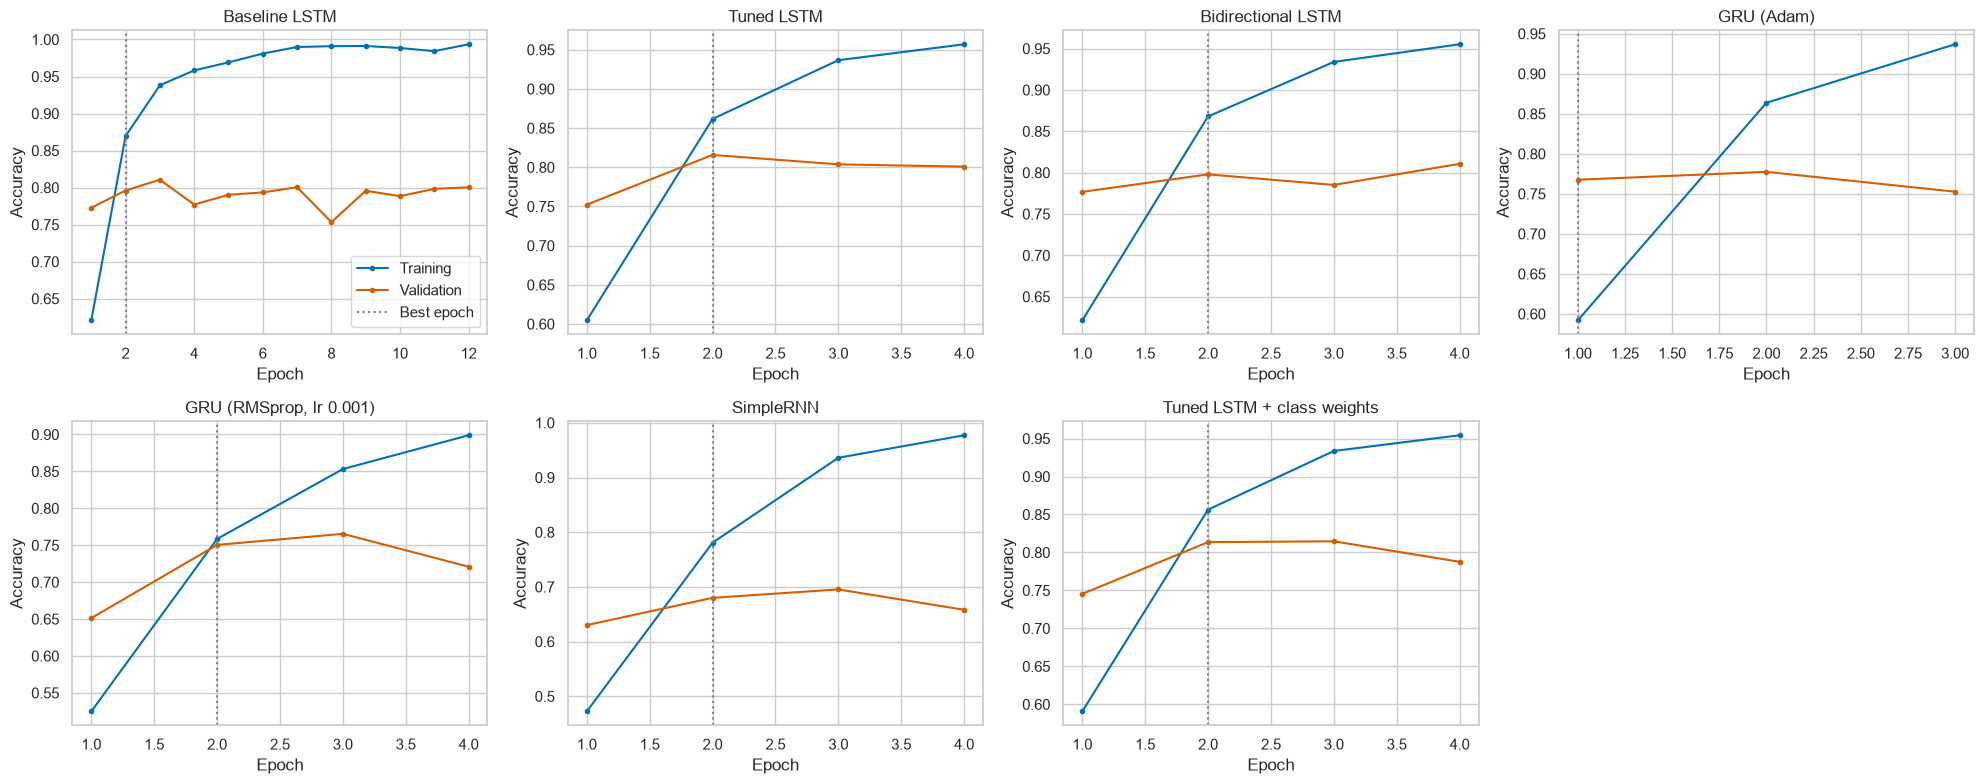

Saved: figures/14_accuracy_curves.png


In [41]:
model_order = ["Baseline LSTM", "Tuned LSTM", "Bidirectional LSTM", "GRU (Adam)",
               "GRU (RMSprop, lr 0.001)", "SimpleRNN", "Tuned LSTM + class weights"]


def plot_curves(metric, ylabel, filename):
    fig, axes = plt.subplots(2, 4, figsize=(20, 8))
    for ax, name in zip(axes.ravel(), model_order):
        h = results[name]["history"]
        epochs = range(1, len(h[metric]) + 1)
        ax.plot(epochs, h[metric], marker="o", ms=3, label="Training", color="#0072B2")
        ax.plot(epochs, h["val_" + metric], marker="o", ms=3, label="Validation", color="#D55E00")
        ax.axvline(results[name]["best_epoch"], color="grey", linestyle=":", label="Best epoch")
        ax.set_title(name)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
    axes.ravel()[0].legend()
    for ax in axes.ravel()[len(model_order):]:
        ax.axis("off")
    plt.tight_layout()
    save_figure(filename)


plot_curves("accuracy", "Accuracy", "14_accuracy_curves.png")

This code draws the accuracy curves for every model, with training accuracy in blue and validation accuracy in orange, and a dotted line marking the best epoch. The curves are the main tool for spotting overfitting. If training accuracy keeps rising while validation accuracy stops rising or falls, the network has started to memorise the training sentences instead of learning general habits of style. Each model gets its own small chart, and the figure is saved as `figures/14_accuracy_curves.png`.

**What the output shows.** Every model shows a large gap between training and validation accuracy. Training accuracy reaches roughly 90 to 98 percent by the end of each run, while validation accuracy stays between about 0.67 and 0.82. This gap is what overfitting looks like, and it explains why early stopping picks epoch 1 or 2 for every model.

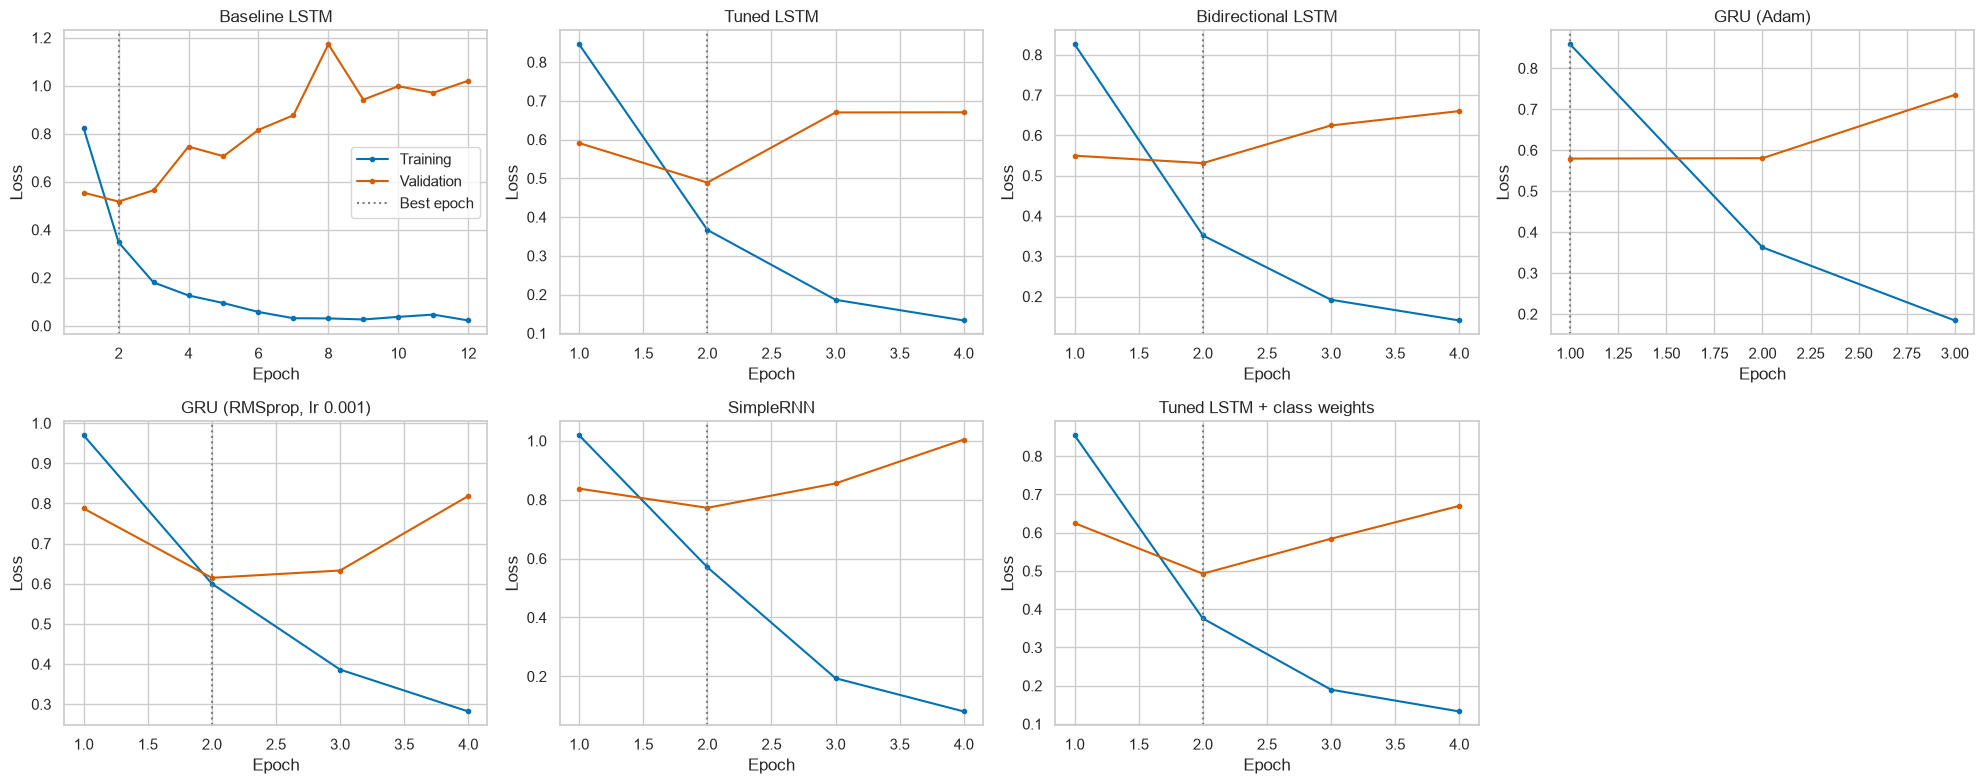

Saved: figures/15_loss_curves.png


In [42]:
plot_curves("loss", "Loss", "15_loss_curves.png")

This code draws the loss curves in the same layout. Loss measures how wrong the predicted probabilities are, so lower is better, and it is more sensitive than accuracy because it also punishes a model for being confidently wrong. The point where the validation loss stops falling and starts to rise is where overfitting begins, and this is the point that early stopping uses to decide when to stop. The figure is saved as `figures/15_loss_curves.png`.

**What the output shows.** The validation loss reaches its lowest point at epoch 1 or 2 for every model and then rises, while the training loss keeps falling. The baseline LSTM makes this clearest, because its validation loss more than doubles from 0.517 at epoch 2 to 1.105 at epoch 12. Early stopping avoids this by restoring the weights from the best epoch.

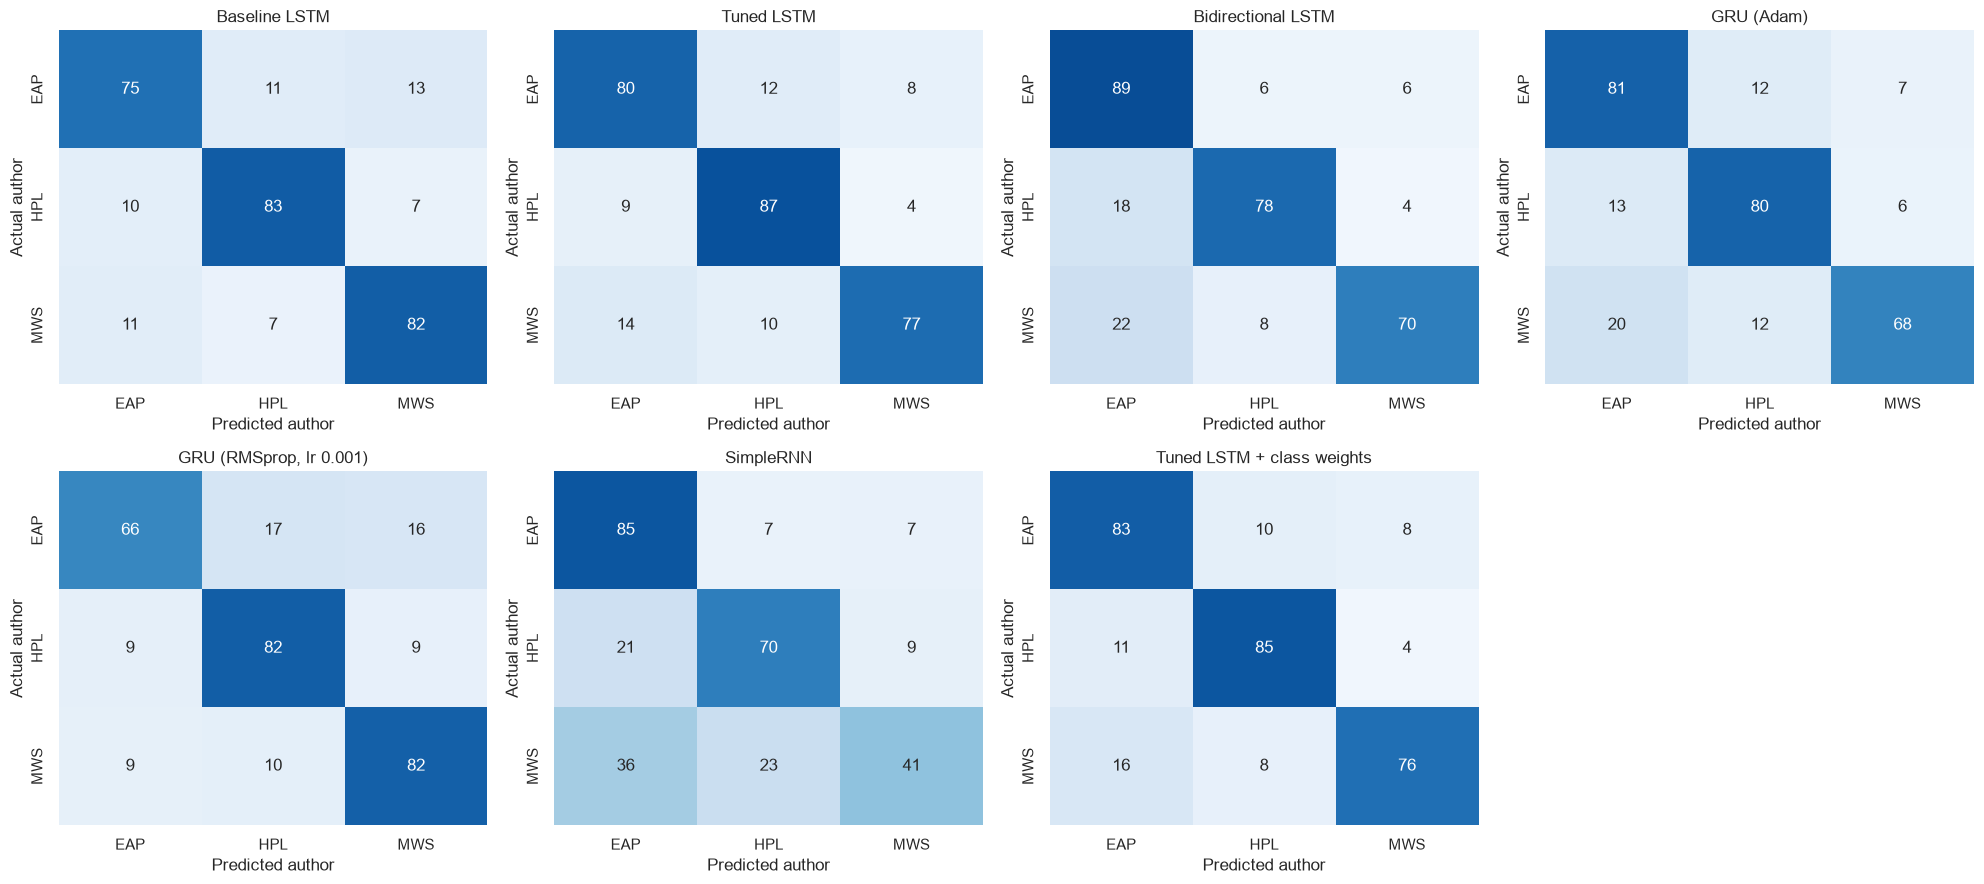

Saved: figures/16_confusion_matrices_all.png


In [43]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, name in zip(axes.ravel(), model_order):
    cm = confusion_matrix(y_test, results[name]["test_prob"].argmax(axis=1))
    cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100
    sns.heatmap(cm_percent, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted author")
    ax.set_ylabel("Actual author")
for ax in axes.ravel()[len(model_order):]:
    ax.axis("off")
plt.tight_layout()
save_figure("16_confusion_matrices_all.png")

This code draws a confusion matrix for every model on the test set. Each row is an actual author and each column is the predicted author, and every cell shows the percentage of that author's sentences that were given that prediction. The diagonal from top left to bottom right shows the sentences that were classified correctly, so a darker diagonal means a better model, and the numbers off the diagonal show which authors get confused with which. Percentages are used instead of raw counts so that the larger EAP class does not dominate the picture. The figure is saved as `figures/16_confusion_matrices_all.png`.

**What the output shows.** For the tuned LSTM the correct percentages are 80 for Poe, 87 for Lovecraft and 77 for Shelley, so no author is neglected. Shelley is the most often mistaken author, and 14 percent of her sentences are called Poe and 10 percent are called Lovecraft. The Bidirectional LSTM is best at Poe (89 percent) but weakest at Shelley (70 percent, with 22 percent labelled Poe). The SimpleRNN is poor for Shelley (56 percent, with 34 percent labelled Poe), and the GRU with RMSprop finds only 66 percent of Poe's sentences.

In [44]:
per_class_rows = []
for name in model_order:
    pred = results[name]["test_prob"].argmax(axis=1)
    report = classification_report(y_test, pred, target_names=class_names, digits=3)
    (out_dir / f"classification_report_{slug(name)}.txt").write_text(f"{name}\n\n{report}")
    precision, recall, f1, support = precision_recall_fscore_support(y_test, pred, labels=range(n_classes))
    for i, author in enumerate(class_names):
        per_class_rows.append({"model": name, "author": author, "precision": precision[i],
                               "recall": recall[i], "f1": f1[i], "support": support[i]})
per_class = pd.DataFrame(per_class_rows)
per_class.round(4).to_csv(out_dir / "per_class_metrics.csv", index=False)

for metric in ["precision", "recall", "f1"]:
    print(f"Test {metric} by author:")
    display(per_class.pivot(index="model", columns="author", values=metric).loc[model_order].round(3))

Test precision by author:


author,EAP,HPL,MWS
model,,,
Baseline LSTM,0.830,0.781,0.775
Tuned LSTM,0.828,0.767,0.842
Bidirectional LSTM,0.751,0.824,0.866
GRU (Adam),0.766,0.732,0.817
"GRU (RMSprop, lr 0.001)",0.834,0.704,0.738
SimpleRNN,0.668,0.668,0.696
Tuned LSTM + class weights,0.806,0.793,0.845


Test recall by author:


author,EAP,HPL,MWS
model,,,
Baseline LSTM,0.754,0.831,0.821
Tuned LSTM,0.802,0.872,0.768
Bidirectional LSTM,0.889,0.781,0.702
GRU (Adam),0.811,0.801,0.682
"GRU (RMSprop, lr 0.001)",0.665,0.824,0.816
SimpleRNN,0.852,0.701,0.413
Tuned LSTM + class weights,0.826,0.855,0.757


Test f1 by author:


author,EAP,HPL,MWS
model,,,
Baseline LSTM,0.790,0.805,0.797
Tuned LSTM,0.814,0.816,0.804
Bidirectional LSTM,0.814,0.802,0.775
GRU (Adam),0.788,0.765,0.743
"GRU (RMSprop, lr 0.001)",0.740,0.759,0.775
SimpleRNN,0.749,0.684,0.518
Tuned LSTM + class weights,0.816,0.823,0.799


This code measures how well each model does for each author separately. Precision answers "when the model says this is Poe, how often is it right", recall answers "of all the real Poe sentences, how many did the model find", and the F1 score combines the two into one number. Looking at the authors separately matters because a model can have a good overall accuracy and still be poor at one author. A full classification report for every model is saved as a text file in the `outputs` folder, and the per-author scores for all models are saved as one CSV file.

**What the output shows.** The tuned LSTM is balanced across the authors, with F1 scores of 0.815 for Poe, 0.816 for Lovecraft and 0.804 for Shelley. Its precision is lowest for Lovecraft (0.767) and its recall is highest for him (0.872), so the model is a little too willing to say Lovecraft. The SimpleRNN's F1 for Shelley is only 0.581, and the GRU with RMSprop has a recall of only 0.665 for Poe. Reading the per-author scores shows problems that a single overall accuracy would hide.

## 10. Model comparison and choosing the best model

This section puts all the models side by side, chooses the best one using the validation set, and then examines that model's errors on the test set.

In [45]:
def metrics_row(name):
    r = results[name]
    val_pred, test_pred = r["val_prob"].argmax(axis=1), r["test_prob"].argmax(axis=1)
    acc = accuracy_score(y_test, test_pred)
    return {
        "model": name, "parameters": r["params"], "epochs_run": r["epochs_run"], "best_epoch": r["best_epoch"],
        "train_seconds": round(r["seconds"], 1),
        "val_loss": log_loss(y_val, r["val_prob"], labels=range(n_classes)),
        "val_accuracy": accuracy_score(y_val, val_pred),
        "val_macro_f1": f1_score(y_val, val_pred, average="macro"),
        "test_accuracy": acc,
        "test_accuracy_ci95": 1.96 * np.sqrt(acc * (1 - acc) / len(y_test)),
        "test_macro_precision": precision_score(y_test, test_pred, average="macro"),
        "test_macro_recall": recall_score(y_test, test_pred, average="macro"),
        "test_macro_f1": f1_score(y_test, test_pred, average="macro"),
        "test_log_loss": log_loss(y_test, r["test_prob"], labels=range(n_classes)),
    }


comparison = pd.DataFrame([metrics_row(n) for n in model_order]).set_index("model")
comparison = comparison.sort_values("val_macro_f1", ascending=False)
comparison.round(4).to_csv(out_dir / "model_comparison.csv")
display(comparison.round(3))

best_name = comparison["val_macro_f1"].idxmax()
print("Best model, chosen by validation macro F1:", best_name)
print("The majority-class baseline (always guess EAP) would score",
      f"{(y_test == class_names.index('EAP')).mean():.3f} accuracy on the test set.")

,parameters,epochs_run,best_epoch,train_seconds,val_loss,val_accuracy,val_macro_f1,test_accuracy,test_accuracy_ci95,test_macro_precision,test_macro_recall,test_macro_f1,test_log_loss
model,,,,,,,,,,,,,
Tuned LSTM,1664003,4,2,13.3,0.489,0.816,0.816,0.812,0.010,0.812,0.814,0.811,0.493
Tuned LSTM + class weights,1664003,4,2,12.1,0.493,0.814,0.815,0.813,0.010,0.815,0.813,0.812,0.489
Baseline LSTM,1581635,12,2,33.9,1.021,0.800,0.802,0.797,0.010,0.795,0.802,0.797,1.021
Bidirectional LSTM,1795971,4,2,34.9,0.531,0.798,0.798,0.800,0.010,0.814,0.790,0.797,0.526
GRU (Adam),1631491,3,1,9.6,0.579,0.768,0.767,0.768,0.011,0.772,0.765,0.765,0.574
"GRU (RMSprop, lr 0.001)",1631491,4,2,14.6,0.615,0.750,0.752,0.757,0.011,0.759,0.768,0.758,0.601
SimpleRNN,1565315,4,2,32.4,0.772,0.680,0.659,0.673,0.012,0.677,0.655,0.650,0.768


Best model, chosen by validation macro F1: Tuned LSTM
The majority-class baseline (always guess EAP) would score 0.403 accuracy on the test set.


This code builds the main comparison table, with one row per model. For each model it records the number of parameters, the number of epochs, the training time, and the validation results, followed by the test results: accuracy with a 95 percent margin of error, and macro precision, macro recall, macro F1 and log loss. "Macro" means the score is worked out for each author separately and then averaged, so each author counts equally regardless of how many sentences they have. Log loss is the same loss used in training, measured on the test set. The models are sorted by validation macro F1, and the best model is chosen by that number and not by the test score, so that the test set stays an honest final exam. The table is saved as `outputs/model_comparison.csv`. The last line states the accuracy of a lazy model that always guesses the biggest class, which is the score every real model must beat.

**What the output shows.** The tuned LSTM is the best model on validation macro F1 (0.816) and it is also best or joint best on the test set, with an accuracy of 0.812 (plus or minus 0.010), a macro F1 of 0.812 and a log loss of 0.493. The always-guess-Poe baseline scores 0.403. The class-weighted version scores 0.813, the baseline LSTM 0.798 and the Bidirectional LSTM 0.799. Those four are within about one and a half percentage points of each other, which is close to the margin of error, so they cannot be separated with confidence. The GRU with Adam (0.768), the GRU with RMSprop (about 0.757) and the SimpleRNN (0.680) are clearly worse. The baseline LSTM's accuracy is close to the tuned model's, but its log loss is more than twice as high (1.119 against 0.493), because it was left to overfit and became over-confident, so the tuning did improve the quality of its probabilities. Three cautions apply. Each model was trained once, the LSTM was the only model whose settings were searched, and the GRU stopped after one good epoch, so the comparison may favour the LSTM slightly. The graphics chip may also give slightly different numbers on another run.

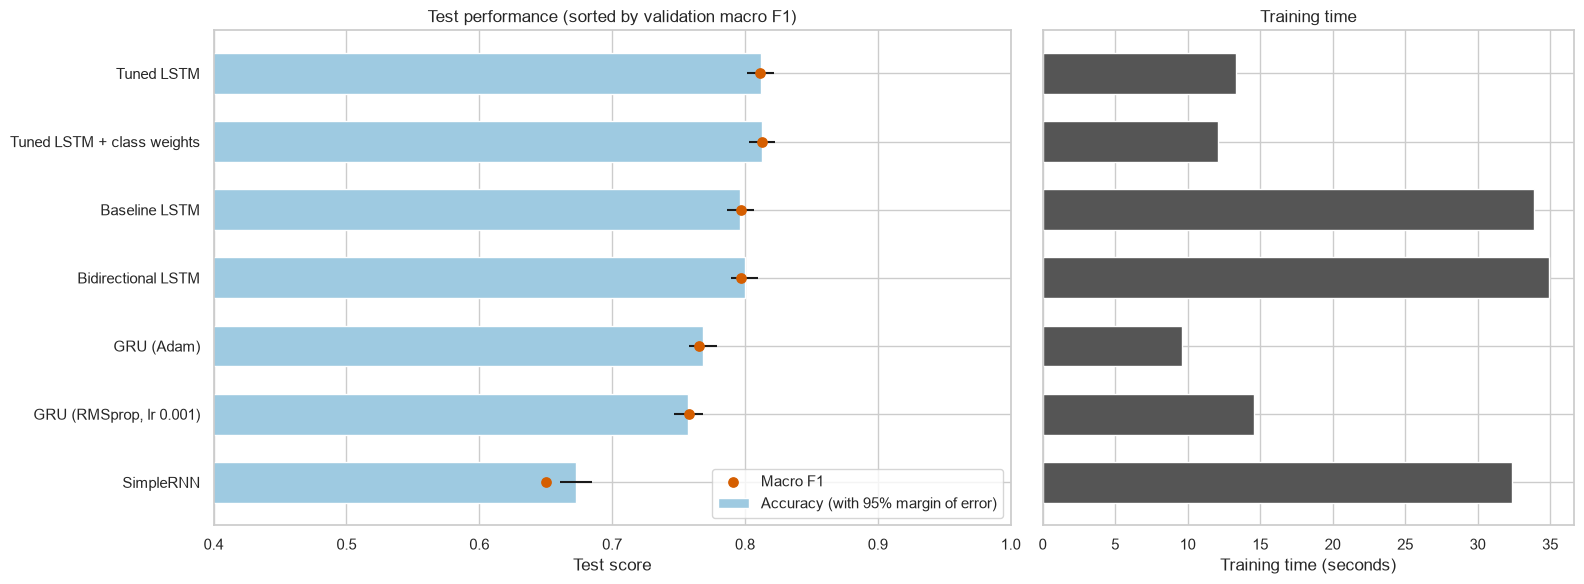

Saved: figures/18_model_comparison.png


In [46]:
order = list(comparison.index)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.5, 1]})
positions = np.arange(len(order))
axes[0].barh(positions, comparison["test_accuracy"], xerr=comparison["test_accuracy_ci95"],
             color="#9ecae1", label="Accuracy (with 95% margin of error)", height=0.6)
axes[0].scatter(comparison["test_macro_f1"], positions, color="#D55E00", zorder=3, s=45, label="Macro F1")
axes[0].set_yticks(positions)
axes[0].set_yticklabels(order)
axes[0].invert_yaxis()
axes[0].set_xlim(0.4, 1.0)
axes[0].set_xlabel("Test score")
axes[0].set_title("Test performance (sorted by validation macro F1)")
axes[0].legend(loc="lower right")
axes[1].barh(positions, comparison["train_seconds"], color="#555555", height=0.6)
axes[1].set_yticks(positions)
axes[1].set_yticklabels([])
axes[1].invert_yaxis()
axes[1].set_xlabel("Training time (seconds)")
axes[1].set_title("Training time")
plt.tight_layout()
save_figure("18_model_comparison.png")

This code draws the comparison as a chart. On the left, each bar is the test accuracy of a model with a thin line showing its 95 percent margin of error, and the orange dot is the macro F1 score. The margin of error is important because the test set is finite, so two models whose bars overlap are not clearly different from each other. On the right, the bars show how long each model took to train. Seeing accuracy and time together shows whether a more complicated model is worth its extra cost. The figure is saved as `figures/18_model_comparison.png`.

**What the output shows.** The chart shows that the four best models overlap within their margins of error, and that the GRU and the SimpleRNN sit clearly lower. The tuned LSTM is also among the cheapest to train at about 12 seconds, while the Bidirectional LSTM takes about three times as long for no gain. The best trade-off between accuracy and cost is therefore the tuned LSTM.

Classification report for the best model: Tuned LSTM

              precision    recall  f1-score   support

         EAP      0.828     0.802     0.814      2370
         HPL      0.767     0.872     0.816      1691
         MWS      0.842     0.768     0.804      1813

    accuracy                          0.812      5874
   macro avg      0.812     0.814     0.811      5874
weighted avg      0.815     0.812     0.812      5874



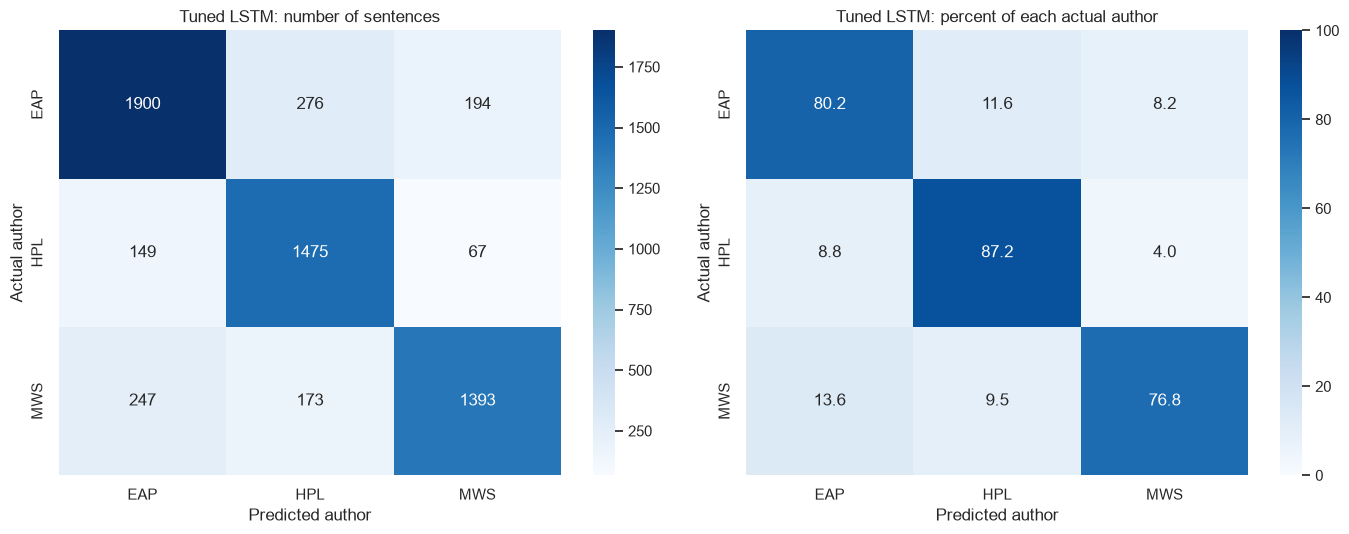

Saved: figures/17_best_model_confusion_matrix.png


In [47]:
best_pred = results[best_name]["test_prob"].argmax(axis=1)
print(f"Classification report for the best model: {best_name}\n")
print(classification_report(y_test, best_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_test, best_pred)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title(f"{best_name}: number of sentences")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True) * 100, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title(f"{best_name}: percent of each actual author")
for ax in axes:
    ax.set_xlabel("Predicted author")
    ax.set_ylabel("Actual author")
plt.tight_layout()
save_figure("17_best_model_confusion_matrix.png")

This code studies the chosen model in detail. It prints the full classification report, which lists precision, recall and F1 for each author together with the overall accuracy and the macro averages. It then draws the confusion matrix twice: once with the number of sentences and once with percentages of each actual author. The counts show the size of each type of mistake, and the percentages make the authors comparable. Reading the off-diagonal cells tells us which pairs of authors the model finds hardest to tell apart. The figure is saved as `figures/17_best_model_confusion_matrix.png`.

**What the output shows.** The tuned LSTM has an overall accuracy of 0.812 on 5,874 unseen sentences, with macro precision 0.812, macro recall 0.814 and macro F1 0.812. For Poe the precision is 0.828 and the recall 0.802, for Lovecraft 0.767 and 0.872, and for Shelley 0.842 and 0.769. Row by row, 80 percent of Poe's sentences are correct, 12 percent are called Lovecraft and 8 percent Shelley. 87 percent of Lovecraft's are correct, and 77 percent of Shelley's are correct with most of the errors going to Poe. The model favours Lovecraft slightly, since he has the lowest precision and the highest recall.

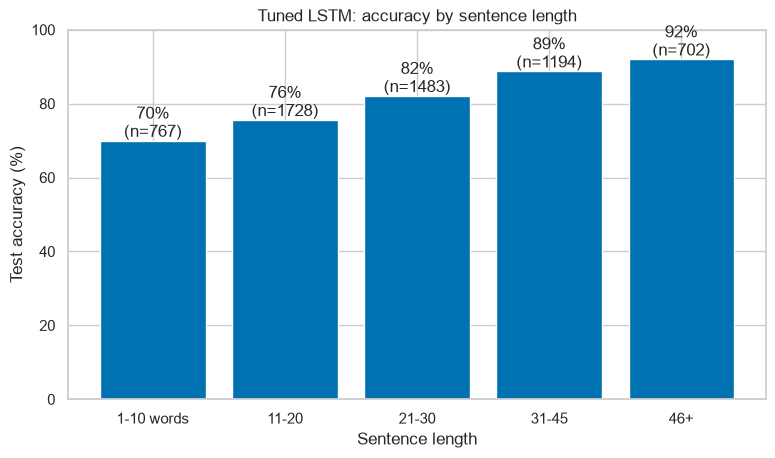

Saved: figures/19_accuracy_by_length.png
Accuracy by the model's confidence:


,accuracy (%),sentences
confidence_group,,
under 50%,45.5,303
50-70%,57.5,954
70-90%,72.4,1205
over 90%,94.0,3412


,text,author,predicted,confidence
16672,"One evening, quitting our inn, we strolled down a shady lane, then up a grassy slope, till we came to an e...",MWS,HPL,1.0
1469,I must have been delirious for I even sought amusement in speculating upon the relative velocities of thei...,EAP,HPL,1.0
15907,"I found that the sparrow uttered none but harsh notes, whilst those of the blackbird and thrush were sweet...",MWS,HPL,1.0
9609,What I saw what I heard what I felt what I thought had about it nothing of the unmistakable idiosyncrasy o...,EAP,HPL,1.0
14073,"He not only shut his mouth and wagged his tail, but absolutely offered me his paw afterward extending his ...",EAP,HPL,1.0
3283,The mower's scythe was at times heard; yet the joyless haymakers after they had listlessly turned the gras...,MWS,HPL,1.0


In [48]:
test_rows = df.loc[text_test.index].copy()
test_rows["predicted"] = [class_names[i] for i in best_pred]
test_rows["confidence"] = results[best_name]["test_prob"].max(axis=1)
test_rows["correct"] = test_rows["predicted"] == test_rows["author"]

# Accuracy by sentence length
test_rows["length_group"] = pd.cut(test_rows["word_count"], bins=[0, 10, 20, 30, 45, 10000],
                                   labels=["1-10 words", "11-20", "21-30", "31-45", "46+"])
by_length = test_rows.groupby("length_group", observed=True)["correct"].agg(["mean", "count"])
by_length["mean"] = by_length["mean"] * 100

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(by_length.index.astype(str), by_length["mean"], color="#0072B2")
for i, (m, n) in enumerate(zip(by_length["mean"], by_length["count"])):
    ax.text(i, m + 1, f"{m:.0f}%\n(n={n})", ha="center")
ax.set_ylim(0, 100)
ax.set_ylabel("Test accuracy (%)")
ax.set_xlabel("Sentence length")
ax.set_title(f"{best_name}: accuracy by sentence length")
save_figure("19_accuracy_by_length.png")

# Accuracy by how confident the model was
test_rows["confidence_group"] = pd.cut(test_rows["confidence"], bins=[0, 0.5, 0.7, 0.9, 1.0],
                                       labels=["under 50%", "50-70%", "70-90%", "over 90%"])
by_conf = test_rows.groupby("confidence_group", observed=True)["correct"].agg(["mean", "count"])
by_conf["mean"] = (by_conf["mean"] * 100).round(1)
print("Accuracy by the model's confidence:")
display(by_conf.rename(columns={"mean": "accuracy (%)", "count": "sentences"}))

# The most confident mistakes
wrong = test_rows[~test_rows["correct"]].nlargest(6, "confidence")
display(wrong[["text", "author", "predicted", "confidence"]].assign(
    text=wrong["text"].str[:150] + "...", confidence=wrong["confidence"].round(2)))

This code looks for where the best model goes wrong. First it groups the test sentences by length and draws the accuracy for each group, which tests the earlier suspicion from the data exploration that short sentences carry too little style to classify. Second it groups the sentences by how confident the model was and reports the accuracy in each group, which shows whether the model's confidence can be trusted. Third it lists the six mistakes where the model was most sure of its answer, so that the actual sentences can be read and judged. Error analysis like this ties the results back to the exploration and shows what the numbers hide. The chart is saved as `figures/19_accuracy_by_length.png`.

**What the output shows.** Accuracy rises steadily with sentence length: 70 percent for sentences of 1 to 10 words (767 sentences), 76 percent for 11 to 20 words, 82 percent for 21 to 30 words, 89 percent for 31 to 45 words and 92 percent for sentences of 46 words or more. This confirms the suspicion from the exploration that short sentences hold too little style for reliable classification. The model's confidence can be trusted to a useful degree. When it is over 90 percent sure, which covers 3,411 of the 5,874 sentences (58 percent), it is right 94.0 percent of the time. When it is between 70 and 90 percent sure it is right 72.4 percent of the time, and when it is under 50 percent sure it is right only 45.9 percent of the time. The six most confident mistakes are all sentences by Shelley or Poe that the model called Lovecraft with a probability of almost 1.0. Why is not clear from the numbers alone, and a likely but untested explanation is that descriptive, atmospheric passages can look like Lovecraft's prose. It does mean that a high confidence is not a guarantee.

## 11. The fan bot

This section turns the chosen model into the bot that the press wanted. A fan types a passage and the bot names the most likely author and shows how confident it is.

In [49]:
best_model = results[best_name]["model"]


def predict_author(text, model=best_model):
    """Return the most likely author for a passage, with the probability for every author."""
    padded = pad_sequences(tokenizer.texts_to_sequences([clean_for_model(text)]),
                           maxlen=maxlen, padding="pre", truncating="post")
    probabilities = model.predict(padded, verbose=0)[0]
    best = int(np.argmax(probabilities))
    return {"guess": class_names[best], "name": author_names[class_names[best]], "confidence": probabilities[best],
            "probabilities": {a: float(p) for a, p in zip(class_names, probabilities)}}


demo_sentences = []
# Three real sentences the model never saw, one per author, taken from the test set.
test_pick = df.loc[text_test.index].groupby("author").sample(1, random_state=seed)
for _, row in test_pick.iterrows():
    demo_sentences.append((f"Test set ({row['author']})", row["text"], row["author"]))
# Four sentences written for this demo. They are not from the dataset.
demo_sentences += [
    ("Written for demo", "The old house stood silent at the end of the lane, and something dreadful seemed to move behind its black windows.", "HPL-style"),
    ("Written for demo", "My heart was heavy with grief as I watched the pale light fade from the sea, and I wept for the friends I had lost.", "MWS-style"),
    ("Written for demo", "I confess, my dear friend, that the singularity of the case perplexed me exceedingly; yet the solution, when at length it came, was simple.", "EAP-style"),
    ("Written for demo", "I texted my friend about the football match tonight, and we agreed to meet at the pub.", "modern English"),
]

rows = []
for source, sentence, expected in demo_sentences:
    result = predict_author(sentence)
    rows.append({"source": source, "expected": expected, "text": sentence[:95] + ("..." if len(sentence) > 95 else ""),
                 "bot's guess": result["guess"], "confidence": round(result["confidence"], 2),
                 **{f"P({a})": round(p, 2) for a, p in result["probabilities"].items()}})
display(pd.DataFrame(rows))

,source,expected,text,bot's guess,confidence,P(EAP),P(HPL),P(MWS)
0,Test set (EAP),EAP,"Upon this I made an effort to get up, in order to put my threat into execution; but the ruffian...",EAP,0.99,0.99,0.00,0.00
1,Test set (HPL),HPL,"The effect of this volume had not left me, and I felt a certain hesitancy in speaking of it; bu...",HPL,0.99,0.01,0.99,0.00
2,Test set (MWS),MWS,"He is an Englishman, and in the midst of national and professional prejudices, unsoftened by cu...",EAP,0.95,0.95,0.02,0.03
3,Written for demo,HPL-style,"The old house stood silent at the end of the lane, and something dreadful seemed to move behind...",HPL,1.00,0.00,1.00,0.00
4,Written for demo,MWS-style,"My heart was heavy with grief as I watched the pale light fade from the sea, and I wept for the...",MWS,0.99,0.00,0.01,0.99
5,Written for demo,EAP-style,"I confess, my dear friend, that the singularity of the case perplexed me exceedingly; yet the s...",EAP,0.76,0.76,0.11,0.13
6,Written for demo,modern English,"I texted my friend about the football match tonight, and we agreed to meet at the pub.",HPL,0.97,0.01,0.97,0.02


This code builds the bot. The `predict_author` function takes any passage of text and applies exactly the same steps as the training data: it cleans the text, converts it to numbers with the saved tokenizer, pads it to the right length, and asks the chosen model for a probability for each author. It returns the most likely author together with all three probabilities, so a fan can see how sure the bot is. The demonstration runs the bot on three real sentences from the test set that the model has never seen, one per author, and on four sentences written for this demonstration, three imitating the style of each author and one in modern English. The modern sentence shows an important limit: the bot must always choose one of the three authors, even when the text is nothing like any of them, so a fan should treat a low confidence as a warning. The sentences written for the demonstration are not from the dataset.

**What the output shows.** On the three real test sentences the bot is right for Poe (probability 0.99) and Lovecraft (0.99) but wrong for Shelley, whose sentence it calls Poe with a probability of 0.95, which is a reminder that about one in five predictions is wrong. On the sentences written for the demonstration it correctly identifies the Lovecraft-style sentence (1.00), the Shelley-style sentence (0.99) and the Poe-style sentence (0.76). The modern English sentence about a football match is called Lovecraft with a probability of 0.97, which shows the limitation described above: the bot has to choose one of three authors, and its confidence does not mean the passage really resembles that author.

## 12. Conclusions, pitfalls and limitations

**What was found.** The dataset is clean, with no missing values or duplicate sentences, and the three authors differ in many small habits: how often they use function words such as "upon", "her" and "the", and how they use semicolons, commas, quotation marks and apostrophes. No single habit separates them, since every effect size is small, which is why a model that reads the whole sentence is needed. The chosen model is the tuned LSTM with 128 units, dropout of 0.5 and early stopping. It reads sentences of up to 64 tokens with a word list of 11,969 entries, and it reaches 81.2 percent accuracy and a macro F1 of 0.812 on 5,874 sentences it has never seen, against 40.3 percent for always guessing Poe. The baseline LSTM, the class-weighted LSTM and the Bidirectional LSTM score within about one and a half points of it, which is close to the margin of error, while the GRU (about 76 to 77 percent) and the SimpleRNN (68 percent) are clearly worse. Early stopping was the change that mattered most, because every model overfitted after one or two epochs. Padding at the start of each sentence instead of the end was the second most important choice, worth about 30 points of accuracy for the LSTM. Class weights made no real difference.

**Pitfalls in the dataset.** Character and place names such as "raymond", "dupin" and "arkham" are among the words most strongly linked to each author, so part of what the model learns is probably the story and not the writing style. Accented letters appear only in Poe and Lovecraft sentences. The file also contains no exclamation marks or dashes, so it has lost part of the style that a human reader would notice. Very short sentences are hard to classify (70 percent accuracy for 1 to 10 words, against 92 percent for sentences of 46 or more), and a few extreme sentences, such as the 861-word one, look like several sentences joined together.

**Limitations.** The training and test sentences come from the same books, so the accuracy on completely new books, or on new writing by the same authors, is likely to be lower. Each model was trained once with one seed, and the graphics chip can give slightly different results between runs. Only the LSTM had its layer size and dropout searched, and the other models reused those settings, which may favour the LSTM a little. The bot must always pick one of three authors, and it called a modern English sentence Lovecraft with a probability of 0.97, so a high confidence does not prove that the text resembles the author.

**Possible next steps.** The results could be made more reliable by repeating each model with several seeds and tuning every model type separately. The pitfalls could be tested by replacing character names with a placeholder and checking how much accuracy drops, and by testing on sentences from books that were not in the training data. Adding an "unknown author" option would make the bot more honest for text that is not from any of the three authors.

## References

Abadi, M. et al. (2015) *TensorFlow: large-scale machine learning on heterogeneous systems*. Available at: https://www.tensorflow.org (Accessed: 20 September 2026).

Anthropic (2026) *Claude Sonnet 5* [Large language model]. Available at: https://claude.ai (Accessed: 20 September 2026).

Bird, S., Klein, E. and Loper, E. (2009) *Natural language processing with Python*. Sebastopol: O'Reilly Media.

Cho, K., van Merrienboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H. and Bengio, Y. (2014) 'Learning phrase representations using RNN encoder-decoder for statistical machine translation', *Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing (EMNLP)*, pp. 1724-1734.

Hochreiter, S. and Schmidhuber, J. (1997) 'Long short-term memory', *Neural Computation*, 9(8), pp. 1735-1780.

Kaggle (2017) *Spooky Author Identification*. Available at: https://www.kaggle.com/c/spooky-author-identification (Accessed: 20 September 2026).

Kruskal, W.H. and Wallis, W.A. (1952) 'Use of ranks in one-criterion variance analysis', *Journal of the American Statistical Association*, 47(260), pp. 583-621.

Miller, G.A. (1995) 'WordNet: a lexical database for English', *Communications of the ACM*, 38(11), pp. 39-41.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M. and Duchesnay, E. (2011) 'Scikit-learn: machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825-2830.

Schuster, M. and Paliwal, K.K. (1997) 'Bidirectional recurrent neural networks', *IEEE Transactions on Signal Processing*, 45(11), pp. 2673-2681.

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I. and Salakhutdinov, R. (2014) 'Dropout: a simple way to prevent neural networks from overfitting', *Journal of Machine Learning Research*, 15(56), pp. 1929-1958.

Stamatatos, E. (2009) 'A survey of modern authorship attribution methods', *Journal of the American Society for Information Science and Technology*, 60(3), pp. 538-556.